In [1]:
# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
from google.colab import drive
drive.mount('/content/drive')
BASE_DATA_DIR = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
GLICKO_REPO_PATH = "/content/drive/MyDrive/TEG02-2025Arellano/Data/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
!pip install lightgbm scikit-learn seaborn joblib confz
# torch y tensorflow dependen del runtime seleccionado en Colab

# ===== TRAZABILIDAD - INICIO =====
import sys, platform, subprocess
from datetime import datetime
from zoneinfo import ZoneInfo

# Al correr en Colab la hora local aparece en UTC, forzamos la GMT-4
tz_caracas=ZoneInfo("America/Caracas")

print("="*70)
print("INICIO DE EJECUCION")
print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))
print("Fecha y hora local:", datetime.now(tz_caracas).strftime("%Y-%m-%d %H:%M:%S"))
print("Entorno (Python):", sys.executable)
print("Version Python:", sys.version.replace("\n", " "))
print("Plataforma:", platform.platform())
print("Versiones de librerias:")
for lib in ["pandas", "numpy", "sklearn", "torch", "lightgbm", "scipy", "matplotlib", "seaborn"]:
    try:
        mod = __import__(lib)
        print(f"  {lib}: {mod.__version__}")
    except:
        print(f"  {lib}: No instalada")
print("="*70)

Mounted at /content/drive
INICIO DE EJECUCION
Fecha y hora UTC: 2026-09-16 20:44:33
Fecha y hora local: 2026-09-16 16:44:33
Entorno (Python): /usr/bin/python3
Version Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
Versiones de librerias:


/tmp/ipykernel_972/889129205.py:21: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))


  pandas: 2.2.3
  numpy: 2.1.3
  sklearn: 1.6.1
  torch: 2.11.0+cpu
  lightgbm: 4.6.0
  scipy: 1.16.3
  matplotlib: 3.10.0
  seaborn: 0.13.2


In [ ]:
# === Selector de modo de entrenamiento ===
# Modos disponibles: "sanity" | "fast" | "deep" | "exhaustive"
TRAINING_MODE = "deep"  # cambia aqui segun lo que quieras ejecutar

# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
#    from google.colab import drive
#    drive.mount('/content/drive')
#    BASE_DATA_DIR = "/content/drive/MyDrive/TEG/AplanarDatos"
#    GLICKO_REPO_PATH = "/content/drive/MyDrive/Glicko2Soccer/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
#    !pip install lightgbm scikit-learn seaborn joblib
#    # torch y tensorflow dependen del runtime seleccionado en Colab

# Rutas base (ajusta si estas en Colab)
#BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
#GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"

# Flags globales controlados por el selector
# Por seguridad inicializamos las banderas
RUN_FULL_TRAINING = False
RUN_SANITY_CHECK = False
FAST_MODE = False
EXHAUSTIVE_MODE = False
DEBUG_MODE = False

# Semilla global para reproducibilidad
Seed = 42

if TRAINING_MODE == "sanity":
    # Sanity: no ejecutar todo el entrenamiento largo; se usa DEBUG_MODE para
    # ejecutar el proceso completo pero sobre un subconjunto (df.head(100)).
    RUN_FULL_TRAINING = False
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = True
elif TRAINING_MODE == "fast":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = True
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "deep":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "exhaustive":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = True
    DEBUG_MODE = False
else:
    raise ValueError(f"TRAINING_MODE invalido: {TRAINING_MODE}")

#BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
DATASET_MODE = "full_lite_recortado"   # o "lite", "full", "full_lite"
DEBUG_MODE = False

In [3]:
import os
import json
import time
import math
import importlib
import random
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss, accuracy_score, classification_report, precision_recall_fscore_support, f1_score
from sklearn.preprocessing import StandardScaler
from scipy.special import iv, gammaln
from scipy.optimize import minimize
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

import gc
from scipy import stats as st
stats=st
import hashlib

# Optional ML frameworks (keep notebook import-safe)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except Exception:
    torch = None
    nn = None
    Dataset = None
    DataLoader = None

try:
    import tensorflow as tf
    from tensorflow import keras
except Exception:
    tf = None
    keras = None

# Workspace path for GlickoSoccer repo (needed before importing modules from it)
#if "GLICKO_REPO_PATH" not in globals():
    #GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"
if not os.path.exists(GLICKO_REPO_PATH):
    raise FileNotFoundError(
        "No se encontro el repo GlickoSoccer. Ajusta GLICKO_REPO_PATH en el selector de modo."
    )
sys.path.insert(0, GLICKO_REPO_PATH)

# Local modules
from G2Av1513 import Glicko2G2A, RatingG2A
from soccer.glicko_soccer import GlickoSoccer
import glicko2 as glicko2_lib

In [4]:
# Carga de los CSV
#if "BASE_DATA_DIR" not in globals():
    #BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
if "DATASET_MODE" not in globals():
    DATASET_MODE = "full_lite_recortado"
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False

DATASET_OPTIONS = {
    "full": ["df_full"],
    "lite": ["df_lite"],
    "full_lite": ["df_full", "df_lite"],
    "full_lite_recortado": ["df_full", "df_lite", "df_lite_recortado"],
}
if DATASET_MODE not in DATASET_OPTIONS:
    raise ValueError(
        f"DATASET_MODE invalido: {DATASET_MODE}. Opciones validas: {list(DATASET_OPTIONS)}"
    )


def resolve_path(candidates):
    for path in candidates:
        if path and os.path.exists(path):
            return path
    joined = "\n".join([str(p) for p in candidates])
    raise FileNotFoundError(
        "No se encontro ningun dataset. Revisa BASE_DATA_DIR y los nombres.\n" + joined
    )


# Datasets base
ruta_lite = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_clean2.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_clean_scaled.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_clean.csv"),
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean.csv",
])
ruta_full = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_full2.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_full_scaled.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_full.csv"),
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full.csv",
])

df_lite = pd.read_csv(ruta_lite)
df_full = pd.read_csv(ruta_full)


def _get_date_series(df, date_col='match_date_from_id'):
    if date_col not in df.columns:
        raise ValueError(f"Falta columna {date_col}")
    dt = pd.to_datetime(df[date_col], errors='coerce')
    if dt.notna().mean() < 0.5:
        dt = pd.to_numeric(df[date_col], errors='coerce')
    return dt


def _extract_match_id_ymd(df, id_col='match_id_new'):
    if id_col not in df.columns:
        raise ValueError(f"Falta columna {id_col}")
    s = df[id_col].astype(str).str.slice(0, 8)
    y = pd.to_numeric(s.str.slice(0, 4), errors='coerce')
    m = pd.to_numeric(s.str.slice(4, 6), errors='coerce')
    d = pd.to_numeric(s.str.slice(6, 8), errors='coerce')
    return y, m, d


def add_pandemic_and_season(df):
    df2 = df.copy()
    dt = _get_date_series(df2)
    dt_series = pd.to_datetime(dt, errors='coerce')
    y_mid, m_mid, d_mid = _extract_match_id_ymd(df2)
    dt_fallback = pd.to_datetime(
        y_mid.astype('Int64') * 10000 + m_mid.astype('Int64') * 100 + d_mid.astype('Int64'),
        format='%Y%m%d', errors='coerce'
    )
    dt_series = dt_series.fillna(dt_fallback)
    start = pd.Timestamp('2020-03-03')
    end = pd.Timestamp('2021-06-06')
    df2['pandemic'] = ((dt_series >= start) & (dt_series <= end)).astype(int)

    calendar_europe = [
        "Bundesliga",
        "ChampionsLeague",
        "EuropaLeague",
        "EuropaConferenceLeague",
        "LaLiga",
        "LigaMX",
        "Ligue1",
        "PremierLeague",
        "SaudiProLeague",
        "SerieA",
        "SuperLeagueGreece",
    ]
    afc_winter = ["AFCChampionsLeagueElite", "AFCChampionsTwo"]
    comp = df2['Competition'].astype(str)
    y = y_mid.fillna(dt_series.dt.year)
    m = m_mid.fillna(dt_series.dt.month)
    is_winter = comp.isin(calendar_europe)
    is_winter |= (comp == 'LigaArgentina') & (y <= 2020)
    is_winter |= comp.isin(afc_winter) & (y >= 2023)
    season = y.copy()
    season = np.where(is_winter & (m >= 8), y + 1, season)
    df2['season'] = pd.Series(season, index=df2.index, dtype="Int64")
    return df2


def build_lite_recortado(df_lite_source, df_full_source):
    if 'match_id_new' not in df_lite_source.columns or 'match_id_new' not in df_full_source.columns:
        raise ValueError("Para construir df_lite_recortado se requiere la columna match_id_new en ambos datasets")
    common_match_ids = pd.Index(df_full_source['match_id_new'].dropna().unique())
    return df_lite_source.loc[df_lite_source['match_id_new'].isin(common_match_ids)].copy()


df_lite_recortado = build_lite_recortado(df_lite, df_full)

df_lite = add_pandemic_and_season(df_lite)
df_full = add_pandemic_and_season(df_full)
df_lite_recortado = add_pandemic_and_season(df_lite_recortado)

DATASET_REGISTRY = {
    "df_lite": df_lite,
    "df_full": df_full,
    "df_lite_recortado": df_lite_recortado,
}
ACTIVE_DATASET_NAMES = DATASET_OPTIONS[DATASET_MODE]
ACTIVE_DATASETS = {name: DATASET_REGISTRY[name] for name in ACTIVE_DATASET_NAMES}


def chronological_split_by_ratio(df, ratio=0.7):
    """Divide el DataFrame manteniendo el orden cronologico (por match_date_from_id)."""
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df


def _ensure_non_empty_split(df_sorted, train_df, test_df):
    if len(df_sorted) >= 2 and (len(train_df) == 0 or len(test_df) == 0):
        train_df = df_sorted.iloc[:-1].copy()
        test_df = df_sorted.iloc[-1:].copy()
    return train_df, test_df


def safe_pct(part, total):
    return (part / total * 100.0) if total else 0.0


train_df_lite_ratio = None
test_df_lite_ratio = None
train_df_full_ratio = None
test_df_full_ratio = None
train_df_lite_recortado_ratio = None
test_df_lite_recortado_ratio = None

for dataset_name, dataset_df in DATASET_REGISTRY.items():
    train_df, test_df = chronological_split_by_ratio(dataset_df, ratio=0.7)
    if DEBUG_MODE:
        df_sorted = dataset_df.sort_values('match_date_from_id').reset_index(drop=True)
        train_df, test_df = _ensure_non_empty_split(df_sorted, train_df, test_df)
    if dataset_name == 'df_lite':
        train_df_lite_ratio, test_df_lite_ratio = train_df, test_df
    elif dataset_name == 'df_full':
        train_df_full_ratio, test_df_full_ratio = train_df, test_df
    elif dataset_name == 'df_lite_recortado':
        train_df_lite_recortado_ratio, test_df_lite_recortado_ratio = train_df, test_df
    print(
        f"{dataset_name} (ratio 70/30) - Entrenamiento: {len(train_df)} ({safe_pct(len(train_df), len(dataset_df)):.1f}%) | "
        f"Prueba: {len(test_df)} ({safe_pct(len(test_df), len(dataset_df)):.1f}%)"
    )

print(f"Modo activo: {DATASET_MODE}")
print(f"Datasets activos: {', '.join(ACTIVE_DATASET_NAMES)}")


df_lite (ratio 70/30) - Entrenamiento: 26473 (70.0%) | Prueba: 11346 (30.0%)
df_full (ratio 70/30) - Entrenamiento: 18946 (70.0%) | Prueba: 8121 (30.0%)
df_lite_recortado (ratio 70/30) - Entrenamiento: 18946 (70.0%) | Prueba: 8121 (30.0%)
Modo activo: full_lite_recortado
Datasets activos: df_full, df_lite, df_lite_recortado


In [ ]:
# Columnas a excluir
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition',
           'home_team', 'away_team', 'home_team_id', 'away_team_id',
           'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
           'draw_prob', 'mu_home', 'mu_away', 'year_from_id', 'month_from_id',
           'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
           'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign',
           'home_OccRat', 'season', 'pandemic', 'home_score', 'away_score', 'outcome']  # draw_prob aún no existe

def get_feature_cols(df):
    """Devuelve lista de columnas numéricas que no están en exclude_cols"""
    return [col for col in df.columns
            if col not in exclude_cols and pd.api.types.is_numeric_dtype(df[col])]

# Verificamos para lite, full y recortado
features_lite = get_feature_cols(df_lite)
print(f"Lite: {len(features_lite)} features")
print("Features:", features_lite[:])

features_full = get_feature_cols(df_full)
print(f"Full: {len(features_full)} features")
print("Features:", features_full[:])

features_lite_recortado = get_feature_cols(df_lite_recortado)
print(f"Lite recortado: {len(features_lite_recortado)} features")
print("Features:", features_lite_recortado[:])


Lite: 33 features
Features: ['travel_km', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30']
Full: 33 features
Features: ['travel_km', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_h

In [ ]:
# --- Bloque: Skellam + LGBM (definiciones) ---
rolling_features = [
    'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10',
    'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30',
    'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10',
    'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30',
    'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10',
    'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30',
    'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10',
    'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30',
 ]

def get_rolling_features(df):
    cols = [c for c in rolling_features if c in df.columns]
    if len(cols) != len(rolling_features):
        missing = [c for c in rolling_features if c not in df.columns]
        print("Advertencia: faltan rolling features:", missing)
    return cols

def skellam_draw_prob(mu1, mu2):
    """Probabilidad de empate según distribución de Skellam (k=0)."""
    mu1 = np.maximum(mu1, 0.0)
    mu2 = np.maximum(mu2, 0.0)
    x = 2 * np.sqrt(mu1 * mu2)
    x = np.clip(x, 0, 700)
    return np.exp(-(mu1 + mu2)) * iv(0, x)

def train_lgbm_and_add_draw_prob(
    train_df,
    test_df,
    model_prefix,
    feature_cols,
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    early_stopping_rounds=10,
    log_eval=50,
 ):
    """Entrena LightGBM (Poisson) y agrega mu_home, mu_away y draw_prob."""
    if not feature_cols:
        raise ValueError("feature_cols esta vacio")
    train_df = train_df.copy()
    test_df = test_df.copy()

    # Split interno de validacion (para early stopping sin tocar el test)
    if 'match_date_from_id' in train_df.columns:
        train_df = train_df.sort_values('match_date_from_id').reset_index(drop=True)
    val_ratio = 0.1
    n_val = max(1, int(len(train_df) * val_ratio)) if len(train_df) >= 10 else 0
    if n_val > 0:
        val_df = train_df.iloc[-n_val:].copy()
        train_main = train_df.iloc[:-n_val].copy()
    else:
        val_df = None
        train_main = train_df

    X_train = train_main[feature_cols]
    y_home_train = train_main['home_goals']
    y_away_train = train_main['away_goals']
    X_test = test_df[feature_cols]

    print(f"\n--- {model_prefix} ---")
    print(f"Entrenamiento: {len(train_df)} partidos | Prueba: {len(test_df)} partidos")

    if val_df is not None:
        X_val = val_df[feature_cols]
        y_home_val = val_df['home_goals']
        y_away_val = val_df['away_goals']
        eval_set_home = [(X_val, y_home_val)]
        eval_set_away = [(X_val, y_away_val)]
        callbacks = [lgb.early_stopping(early_stopping_rounds), lgb.log_evaluation(log_eval)]
    else:
        eval_set_home = None
        eval_set_away = None
        callbacks = [lgb.log_evaluation(log_eval)]

    model_home = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_home.fit(
        X_train, y_home_train,
        eval_set=eval_set_home,
        callbacks=callbacks
    )

    model_away = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_away.fit(
        X_train, y_away_train,
        eval_set=eval_set_away,
        callbacks=callbacks
    )

    # Predecir y calcular draw_prob
    X_train_full = train_df[feature_cols]
    train_df['mu_home'] = model_home.predict(X_train_full)
    train_df['mu_away'] = model_away.predict(X_train_full)
    train_df['draw_prob'] = train_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    test_df['mu_home'] = model_home.predict(X_test)
    test_df['mu_away'] = model_away.predict(X_test)
    test_df['draw_prob'] = test_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

    joblib.dump(model_home, f"{model_prefix}_home_model.pkl")
    joblib.dump(model_away, f"{model_prefix}_away_model.pkl")
    print(f"Modelos guardados: {model_prefix}_home/away_model.pkl")

    return full_df, model_home, model_away

In [7]:
# --- Bloque: Glicko (definiciones) ---
def prepare_for_glicko(df):
    df2 = df.copy()
    # match_id (unico)
    if 'match_id_new' not in df2.columns:
        df2['match_id_new'] = range(len(df2))

    # Fecha y season
    try:
        df2['season'] = df2['match_id_new'].astype(str).str[:4].astype(int)
    except:
        df2['match_date_from_id'] = pd.to_datetime(df2['match_date_from_id'], errors='coerce')
        df2['season'] = df2['match_date_from_id'].dt.year

    # Verificar seasons nulas
    if df2['season'].isna().any():
        print("Advertencia: algunos partidos no tienen anio asignado. Se rellenan con 1900")
        df2['season'] = df2['season'].fillna(1900).astype(int)

    # tournament_type: 1 = liga (por defecto)
    df2['tournament_type'] = 1
    continental_keywords = [
        'ChampionsLeague', 'EuropaLeague', 'EuropaConferenceLeague',
        'AFCChampionsLeagueElite', 'AFCChampionsTwo', 'CONCACAFChampionsLeague', 'FIFAClubWorldCup',
        'CopaLibertadores', 'CopaSudamericana',
    ]
    mask = df2['Competition'].str.contains('|'.join(continental_keywords), case=False, na=False)
    df2.loc[mask, 'tournament_type'] = 3

    # outcome
    df2['outcome'] = np.where(df2['home_goals'] > df2['away_goals'], 'H',
                              np.where(df2['home_goals'] < df2['away_goals'], 'A', 'D'))

    # is_pandemic
    if 'is_pandemic' in df2.columns:
        df2['is_pandemic'] = df2['is_pandemic'].astype(bool)
    else:
        df2['is_pandemic'] = False

    # draw_probability (probabilidad cruda)
    df2['draw_probability'] = df2['draw_prob'].fillna(0.26)
    # NOTA METODOLOGICA: El motor G2Av1513.py recibe draw_prob en escala de
    # probabilidad (0,1) y aplica internamente la transformacion logit como
    # mejora de estabilidad numerica sobre el modelo canonico de Shelopugin-
    # Sirotkin. No se aplica logit en el notebook; la conversion ocurre dentro
    # del metodo _draw_logit_from_prob del motor G2Av1513.py.

    # tournament (nombre competicion)
    df2['tournament'] = df2['Competition']

    return df2

def prepare_glicko_input(df):
    df_prep = prepare_for_glicko(df)
    df_prep = df_prep.rename(columns={
        'match_date_from_id': 'date',
        'match_id_new': 'match_id',
    })
    assert 'date' in df_prep.columns, "Falta columna 'date'"
    assert 'match_id' in df_prep.columns, "Falta columna 'match_id'"
    return df_prep

In [8]:
# Importante, aqui definimos como evaluar el modelo Skellam/LGBM

def evaluate_model(train_df, test_df, model_home, model_away, feature_cols, dataset_name):
    """
    Evalua los modelos por separado en train/test usando el split 70/30.
    """
    X_train = train_df[feature_cols]
    y_home_train = train_df['home_goals']
    y_away_train = train_df['away_goals']
    X_test = test_df[feature_cols]
    y_home_test = test_df['home_goals']
    y_away_test = test_df['away_goals']

    mu_home_train = model_home.predict(X_train)
    mu_away_train = model_away.predict(X_train)
    mu_home_test = model_home.predict(X_test)
    mu_away_test = model_away.predict(X_test)

    mae_home_train = mean_absolute_error(y_home_train, mu_home_train)
    mae_away_train = mean_absolute_error(y_away_train, mu_away_train)
    mae_home_test = mean_absolute_error(y_home_test, mu_home_test)
    mae_away_test = mean_absolute_error(y_away_test, mu_away_test)

    draw_prob_train = skellam_draw_prob(mu_home_train, mu_away_train)
    draw_prob_test = skellam_draw_prob(mu_home_test, mu_away_test)

    real_draw_train = (y_home_train == y_away_train).astype(int)
    real_draw_test = (y_home_test == y_away_test).astype(int)

    def log_loss_binary(prob_draw, y_true):
        prob_draw = np.clip(prob_draw, 1e-15, 1 - 1e-15)
        return -np.mean(y_true * np.log(prob_draw) + (1 - y_true) * np.log(1 - prob_draw))

    log_loss_train = log_loss_binary(draw_prob_train, real_draw_train)
    log_loss_test = log_loss_binary(draw_prob_test, real_draw_test)

    freq_draw_train = real_draw_train.mean()
    freq_draw_test = real_draw_test.mean()
    mean_pred_draw_train = draw_prob_train.mean()
    mean_pred_draw_test = draw_prob_test.mean()

    print(f"\n========== {dataset_name.upper()} ==========")
    print(f"MAE home  - train: {mae_home_train:.4f} | test: {mae_home_test:.4f}")
    print(f"MAE away  - train: {mae_away_train:.4f} | test: {mae_away_test:.4f}")
    print(f"LogLoss draw - train: {log_loss_train:.6f} | test: {log_loss_test:.6f}")
    print(f"Frecuencia empate real   - train: {freq_draw_train:.4f} | test: {freq_draw_test:.4f}")
    print(f"Prob. empate pred. media - train: {mean_pred_draw_train:.4f} | test: {mean_pred_draw_test:.4f}")

    return {
        'mae_home_train': mae_home_train, 'mae_home_test': mae_home_test,
        'mae_away_train': mae_away_train, 'mae_away_test': mae_away_test,
        'log_loss_train': log_loss_train, 'log_loss_test': log_loss_test,
        'freq_draw_train': freq_draw_train, 'freq_draw_test': freq_draw_test,
        'mean_pred_draw_train': mean_pred_draw_train, 'mean_pred_draw_test': mean_pred_draw_test
    }

In [ ]:
# Esto es para medir su calibracion

def plot_calibration(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)
    draw_prob = skellam_draw_prob(mu_home, mu_away)
    real_draw = (test_df['home_goals'] == test_df['away_goals']).astype(int)

    bins = np.linspace(0, 1, 11)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    observed = []
    for i in range(len(bins) - 1):
        mask = (draw_prob >= bins[i]) & (draw_prob < bins[i + 1])
        if mask.sum() > 0:
            observed.append(real_draw[mask].mean())
        else:
            observed.append(np.nan)

    plt.figure(figsize=(6, 5))
    plt.plot(bin_centers, observed, 'o-', label='Observado')
    plt.plot([0, 1], [0, 1], 'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibracion de draw_prob - {dataset_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

In [10]:
# Definimos los residuales
def plot_residuals(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    y_home_true = test_df['home_goals']
    y_away_true = test_df['away_goals']
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)

    resid_home = y_home_true - mu_home
    resid_away = y_away_true - mu_away

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(resid_home, bins=20, alpha=0.7, label='Home')
    axes[0].set_title(f'{dataset_name} - Residuos goles locales')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[1].hist(resid_away, bins=20, alpha=0.7, label='Away', color='orange')
    axes[1].set_title(f'{dataset_name} - Residuos goles visitantes')
    axes[1].axvline(0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()

    print(f"Residuos home - media: {resid_home.mean():.3f}, std: {resid_home.std():.3f}")
    print(f"Residuos away - media: {resid_away.mean():.3f}, std: {resid_away.std():.3f}")

[Skellam/LGBM] DATASET_MODE=full_lite_recortado | Datasets activos: ['full', 'lite', 'lite_recortado']

--- full_ratio ---
Entrenamiento: 18946 partidos | Prueba: 8121 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.971004
[100]	valid_0's l1: 0.958147
[150]	valid_0's l1: 0.957162
Early stopping, best iteration is:
[141]	valid_0's l1: 0.957022
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.856448
Early stopping, best iteration is:
[50]	valid_0's l1: 0.856448
Modelos guardados: full_ratio_home/away_model.pkl

--- lite_ratio ---
Entrenamiento: 26473 partidos | Prueba: 11346 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.941753
[100]	valid_0's l1: 0.929606
[150]	valid_0's l1: 0.926802
Early stopping, best iteration is:
[156]	valid_0's l1: 0.926496
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[36]	valid_0's l1: 0.798276


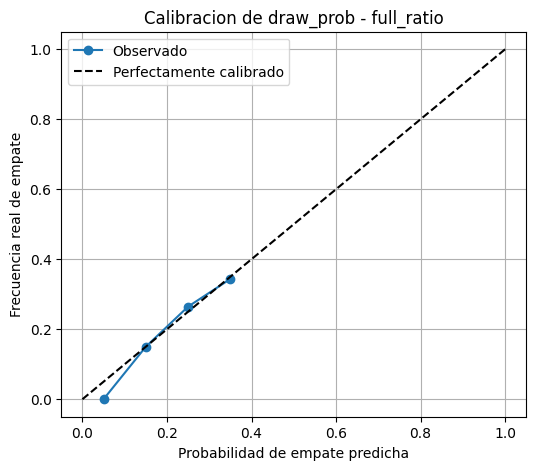

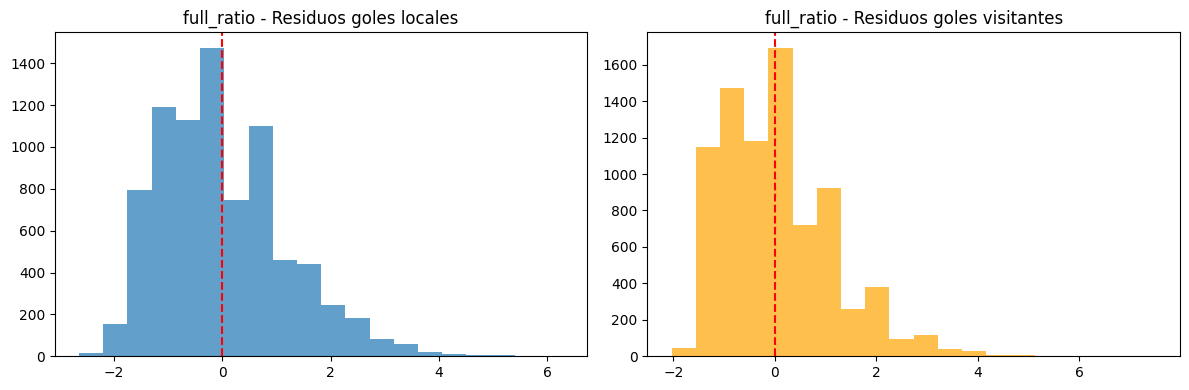

Residuos home - media: 0.002, std: 1.171
Residuos away - media: 0.035, std: 1.089


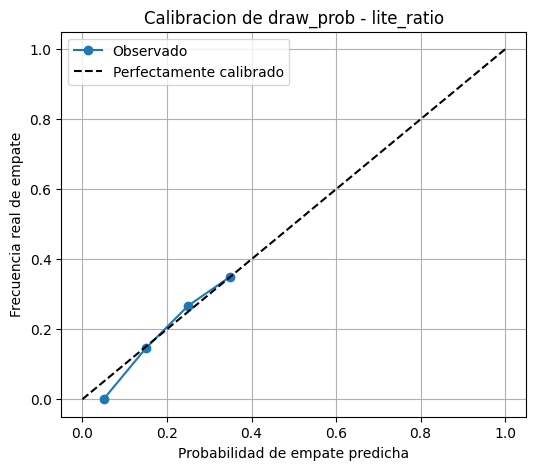

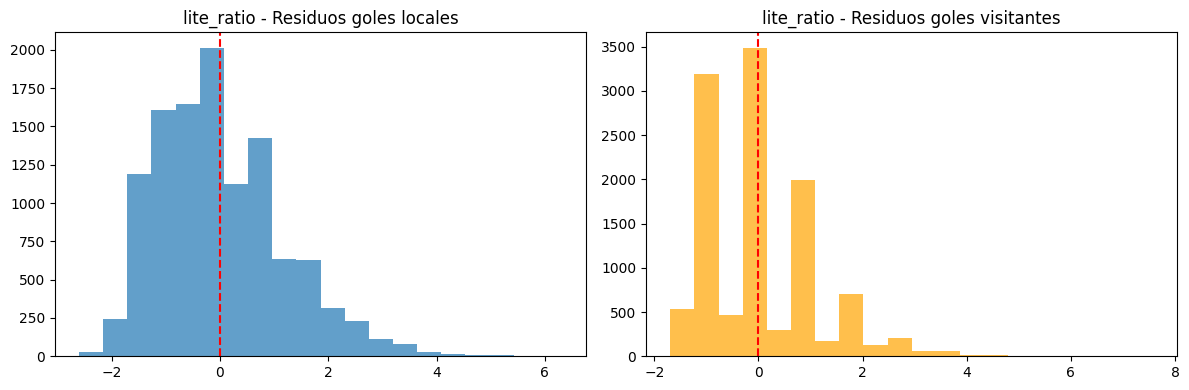

Residuos home - media: 0.003, std: 1.166
Residuos away - media: 0.030, std: 1.089


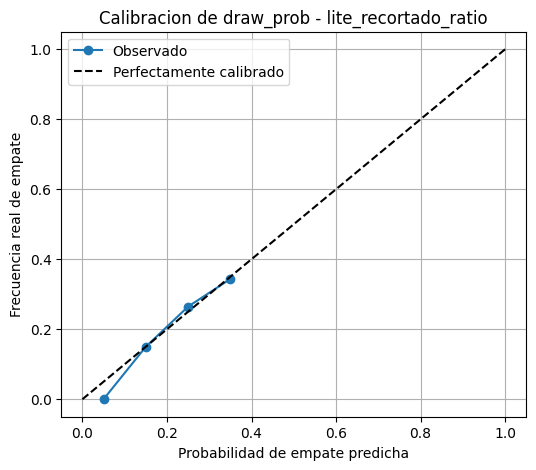

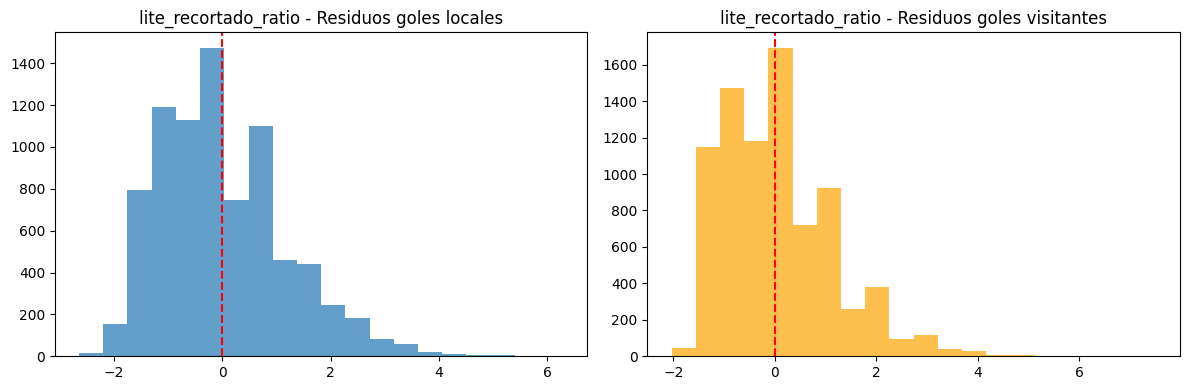

Residuos home - media: 0.002, std: 1.171
Residuos away - media: 0.035, std: 1.089


In [11]:
# === Skellam/LGBM (entrenamientos, calibracion y graficos) ===

# Controles globales (se comparten con el resto de bloques)
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "PARALLEL_SKELLAM" not in globals():
    PARALLEL_SKELLAM = False
if "N_JOBS" not in globals():
    _cpu = os.cpu_count() or 2
    N_JOBS = max(1, _cpu - 1)
if "Seed" not in globals():
    Seed = 42

random.seed(Seed)
np.random.seed(Seed)
if tf is not None:
    tf.random.set_seed(Seed)
if torch is not None:
    torch.manual_seed(Seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(Seed)
    try:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass

# Skellam/LGBM siempre se ejecuta para generar dataset_draw_ratio
RUN_SKELLAM_LGBM = True

# Resolver datasets activos a partir de DATASET_MODE (definido en celda 4)
name_map = {
    "df_lite": "lite",
    "df_full": "full",
    "df_lite_recortado": "lite_recortado",
}
reverse_map = {v: k for k, v in name_map.items()}
active_short_names = []
if "ACTIVE_DATASET_NAMES" in globals():
    active_short_names = [name_map[n] for n in ACTIVE_DATASET_NAMES if n in name_map]
if not active_short_names:
    active_short_names = ["lite"]

ratio_split_map = {
    "lite": (train_df_lite_ratio, test_df_lite_ratio),
    "full": (train_df_full_ratio, test_df_full_ratio),
    "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
}
frame_map = {
    "lite": df_lite,
    "full": df_full,
    "lite_recortado": df_lite_recortado,
}

datasets = {}
dataset_frames = {}
for dataset_name in active_short_names:
    train_test = ratio_split_map.get(dataset_name)
    if train_test is None:
        continue
    train_df, test_df = train_test
    if train_df is None or test_df is None:
        continue
    datasets[dataset_name] = {"ratio": (train_df, test_df)}
    dataset_frames[dataset_name] = frame_map[dataset_name]

if not datasets:
    raise ValueError("No hay datasets activos con split ratio preparado. Ejecuta primero la celda 4.")

print(f"[Skellam/LGBM] DATASET_MODE={DATASET_MODE} | Datasets activos: {list(datasets.keys())}")

dataset_draw_ratio = None
skellam_results = None

# Parametros de entrenamiento
if FAST_MODE:
    LGBM_N_ESTIMATORS = 80
    LGBM_LR = 0.08
    LGBM_MAX_DEPTH = 4
    LGBM_EARLY_STOP = 5
    LGBM_LOG_EVAL = 100
else:
    LGBM_N_ESTIMATORS = 200
    LGBM_LR = 0.05
    LGBM_MAX_DEPTH = 5
    LGBM_EARLY_STOP = 10
    LGBM_LOG_EVAL = 50

def _skellam_job(dataset_name, split_name, train_df, test_df):
    feature_cols = get_rolling_features(train_df)
    model_prefix = f"{dataset_name}_{split_name}"
    df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
        train_df,
        test_df,
        model_prefix,
        feature_cols,
        n_estimators=LGBM_N_ESTIMATORS,
        learning_rate=LGBM_LR,
        max_depth=LGBM_MAX_DEPTH,
        early_stopping_rounds=LGBM_EARLY_STOP,
        log_eval=LGBM_LOG_EVAL,
    )
    return dataset_name, split_name, df_with_draw, model_home, model_away

if RUN_SKELLAM_LGBM:
    skellam_results = {}
    if PARALLEL_SKELLAM:
        jobs = []
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                jobs.append((dataset_name, split_name, train_df, test_df))
        results = joblib.Parallel(n_jobs=N_JOBS)(
            joblib.delayed(_skellam_job)(dataset_name, split_name, train_df, test_df)
            for dataset_name, split_name, train_df, test_df in jobs
        )
        for dataset_name, split_name, df_with_draw, model_home, model_away in results:
            skellam_results[(dataset_name, split_name)] = {
                "df_with_draw": df_with_draw,
                "model_home": model_home,
                "model_away": model_away,
            }
    else:
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                feature_cols = get_rolling_features(train_df)
                model_prefix = f"{dataset_name}_{split_name}"
                df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
                    train_df,
                    test_df,
                    model_prefix,
                    feature_cols,
                    n_estimators=LGBM_N_ESTIMATORS,
                    learning_rate=LGBM_LR,
                    max_depth=LGBM_MAX_DEPTH,
                    early_stopping_rounds=LGBM_EARLY_STOP,
                    log_eval=LGBM_LOG_EVAL,
                )
                skellam_results[(dataset_name, split_name)] = {
                    "df_with_draw": df_with_draw,
                    "model_home": model_home,
                    "model_away": model_away,
                }

    eval_targets = [(dataset_name, "ratio") for dataset_name in datasets.keys()]

    for dataset_name, split_name in eval_targets:
        df_with_draw = skellam_results[(dataset_name, split_name)]["df_with_draw"]
        desc = df_with_draw["draw_prob"].describe()
        print(f"\n[{dataset_name}/{split_name}] draw_prob stats:")
        print(desc)

    # Guardar salidas por dataset activo
    out_name_map = {
        "lite": "matches_final_model_clean_with_draw_ratio.csv",
        "full": "matches_final_model_full_with_draw_ratio.csv",
        "lite_recortado": "matches_final_model_clean_recortado_with_draw_ratio.csv",
    }
    dataset_draw_ratio = {}
    for dataset_name, _ in eval_targets:
        df_with_draw = skellam_results[(dataset_name, "ratio")]["df_with_draw"]
        dataset_draw_ratio[dataset_name] = df_with_draw
        out_path = os.path.join(BASE_DATA_DIR, out_name_map[dataset_name])
        df_with_draw.to_csv(out_path, index=False)
        print(f"[{dataset_name}] guardado en: {out_path}")
        print(f"[{dataset_name}] draw_prob (primeros 5):")
        print(df_with_draw[["home_goals", "away_goals", "draw_prob"]].head())

    # Exponer variables de compatibilidad hacia celdas posteriores
    if "lite" in dataset_draw_ratio:
        df_lite_reentrenado = dataset_draw_ratio["lite"]
    if "full" in dataset_draw_ratio:
        df_full_reentrenado = dataset_draw_ratio["full"]
    if "lite_recortado" in dataset_draw_ratio:
        df_lite_recortado_reentrenado = dataset_draw_ratio["lite_recortado"]

    # Evaluacion MAE + logloss (resumen conjunto)
    metrics_rows = []
    for dataset_name, split_name in eval_targets:
        train_df, test_df = datasets[dataset_name][split_name]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, split_name)]["model_home"]
        model_away = skellam_results[(dataset_name, split_name)]["model_away"]
        metrics = evaluate_model(
            train_df, test_df, model_home, model_away, feature_cols, f"{dataset_name}_{split_name}"
        )
        metrics_rows.append({
            "dataset": dataset_name,
            "split": split_name,
            "mae_home_test": metrics["mae_home_test"],
            "mae_away_test": metrics["mae_away_test"],
            "log_loss_test": metrics["log_loss_test"],
            "mean_pred_draw_test": metrics["mean_pred_draw_test"],
        })

    metrics_skellam_summary = pd.DataFrame(metrics_rows).sort_values(["dataset", "split"]).reset_index(drop=True)
    print("\n=== Resumen Skellam/LGBM por dataset activo ===")
    print(metrics_skellam_summary)

    # Calibracion y residuos para cada dataset activo (split ratio)
    for dataset_name, _ in eval_targets:
        train_df, test_df = datasets[dataset_name]["ratio"]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, "ratio")]["model_home"]
        model_away = skellam_results[(dataset_name, "ratio")]["model_away"]
        plot_calibration(test_df, model_home, model_away, feature_cols, f"{dataset_name}_ratio")
        plot_residuals(test_df, model_home, model_away, feature_cols, f"{dataset_name}_ratio")
else:
    dataset_draw_ratio = None
    fallback_map = {
        "lite": "df_lite_reentrenado",
        "full": "df_full_reentrenado",
        "lite_recortado": "df_lite_recortado_reentrenado",
    }
    for dataset_name in active_short_names:
        gname = fallback_map.get(dataset_name)
        if gname and gname in globals():
            if dataset_draw_ratio is None:
                dataset_draw_ratio = {}
            dataset_draw_ratio[dataset_name] = globals()[gname]


In [12]:
# === RRNN (entrenamiento separado) ===

if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "EXHAUSTIVE_MODE" not in globals():
    EXHAUSTIVE_MODE = False
if "Seed" not in globals():
    Seed = 42

RUN_RRNN = True
if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_RRNN = False

if RUN_RRNN:
    if dataset_draw_ratio is None:
        print("RRNN omitido: dataset_draw_ratio no disponible")
    elif torch is None:
        print("PyTorch no disponible: se omite RRNN")
    else:
        random.seed(Seed)
        np.random.seed(Seed)
        torch.manual_seed(Seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(Seed)
        if tf is not None:
            tf.random.set_seed(Seed)
        try:
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        except Exception:
            pass

        for dataset_name, df_rrnn in dataset_draw_ratio.items():
            print(f"\n[RRNN] dataset={dataset_name}")
            df_rrnn = df_rrnn.copy()
            if EXHAUSTIVE_MODE:
                seq_len = 10
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 60
                lr = 8e-4
                weight_decay = 1e-4
                hidden_size = 128
                dropout = 0.2
            elif FAST_MODE:
                seq_len = 6
                train_ratio = 0.7
                val_ratio = 0.08
                batch_size = 256
                epochs = 8
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 48
                dropout = 0.2
            else:
                seq_len = 8
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 30
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 64
                dropout = 0.2
            min_prob = 1e-15

            exclude_cols = [
                "match_id_new", "match_date_from_id", "Competition",
                "home_team", "away_team", "home_team_id", "away_team_id",
                "home_goals", "away_goals", "home_Goals", "away_Goals",
                "year_from_id", "month_from_id",
                "mu_home", "mu_away", 
                'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10',
                'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30',
                'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10',
                'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30',
                'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10',
                'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30',
                'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10',
                'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30', 'home_OccRat',
            ]
            numeric_cols = [c for c in df_rrnn.columns if pd.api.types.is_numeric_dtype(df_rrnn[c])]
            feature_cols = [c for c in numeric_cols if c not in exclude_cols]
            if "draw_prob" not in feature_cols and "draw_prob" in df_rrnn.columns:
                feature_cols.append("draw_prob")

            df_rrnn = df_rrnn.sort_values("match_date_from_id").reset_index(drop=True)
            df_rrnn[feature_cols] = df_rrnn[feature_cols].fillna(0.0)

            hist_extra_cols = ["is_home", "goals_for", "goals_against", "result"]
            base_dim = len(feature_cols)
            extra_dim = len(hist_extra_cols)
            hist_dim = base_dim + extra_dim

            def outcome_label(row):
                if row["home_goals"] > row["away_goals"]:
                    return 0  # Home win
                if row["home_goals"] < row["away_goals"]:
                    return 2  # Away win
                return 1  # Draw

            def build_hist_vec(row, side):
                is_home = 1.0 if side == "home" else 0.0
                goals_for = float(row["home_goals"] if side == "home" else row["away_goals"])
                goals_against = float(row["away_goals"] if side == "home" else row["home_goals"])
                if goals_for > goals_against:
                    result = 1.0
                elif goals_for < goals_against:
                    result = -1.0
                else:
                    result = 0.0
                base = [float(row[c]) for c in feature_cols]
                return np.array(base + [is_home, goals_for, goals_against, result], dtype=np.float32)

            team_hist = {}
            samples = []

            for idx, row in df_rrnn.iterrows():
                home = row["home_team"]
                away = row["away_team"]
                home_hist = team_hist.get(home, [])
                away_hist = team_hist.get(away, [])

                def pad_seq(seq):
                    if len(seq) >= seq_len:
                        return np.stack(seq[-seq_len:], axis=0)
                    pad = [np.zeros(hist_dim, dtype=np.float32) for _ in range(seq_len - len(seq))]
                    return np.stack(pad + seq, axis=0)

                home_seq = pad_seq(home_hist)
                away_seq = pad_seq(away_hist)
                cur_feat = np.array([float(row[c]) for c in feature_cols], dtype=np.float32)
                label = outcome_label(row)
                samples.append({
                    "idx": idx,
                    "home_seq": home_seq,
                    "away_seq": away_seq,
                    "cur_feat": cur_feat,
                    "label": label,
                })

                team_hist.setdefault(home, []).append(build_hist_vec(row, "home"))
                team_hist.setdefault(away, []).append(build_hist_vec(row, "away"))

            n_total = len(samples)
            n_train = int(n_total * train_ratio)
            n_val = int(n_train * val_ratio)
            train_samples = samples[: n_train - n_val]
            val_samples = samples[n_train - n_val : n_train]
            test_samples = samples[n_train :]

            def stack_base(samples_list):
                cur = np.stack([s["cur_feat"] for s in samples_list], axis=0)
                hist = np.stack([s["home_seq"] for s in samples_list] + [s["away_seq"] for s in samples_list], axis=0)
                hist_base = hist[:, :, :base_dim].reshape(-1, base_dim)
                return cur, hist_base

            cur_train, hist_base_train = stack_base(train_samples)
            base_scaler = StandardScaler().fit(np.vstack([cur_train, hist_base_train]))
            extra_scaler = StandardScaler().fit(
                np.stack([s["home_seq"] for s in train_samples], axis=0)[:, :, base_dim:].reshape(-1, extra_dim)
            )

            def apply_scaling(samples_list):
                for s in samples_list:
                    s["cur_feat"] = base_scaler.transform(s["cur_feat"].reshape(1, -1)).reshape(-1)
                    h_base = base_scaler.transform(s["home_seq"][:, :base_dim])
                    h_extra = extra_scaler.transform(s["home_seq"][:, base_dim:])
                    s["home_seq"] = np.concatenate([h_base, h_extra], axis=1)
                    a_base = base_scaler.transform(s["away_seq"][:, :base_dim])
                    a_extra = extra_scaler.transform(s["away_seq"][:, base_dim:])
                    s["away_seq"] = np.concatenate([a_base, a_extra], axis=1)

            apply_scaling(train_samples)
            apply_scaling(val_samples)
            apply_scaling(test_samples)

            class MatchDataset(Dataset):
                def __init__(self, samples_list):
                    self.samples = samples_list
                def __len__(self):
                    return len(self.samples)
                def __getitem__(self, idx):
                    s = self.samples[idx]
                    return (
                        torch.tensor(s["home_seq"], dtype=torch.float32),
                        torch.tensor(s["away_seq"], dtype=torch.float32),
                        torch.tensor(s["cur_feat"], dtype=torch.float32),
                        torch.tensor(s["label"], dtype=torch.long),
                    )

            train_loader = DataLoader(MatchDataset(train_samples), batch_size=batch_size, shuffle=True)
            val_loader = DataLoader(MatchDataset(val_samples), batch_size=batch_size, shuffle=False)
            test_loader = DataLoader(MatchDataset(test_samples), batch_size=batch_size, shuffle=False)

            class RRNN(nn.Module):
                def __init__(self, hist_dim, cur_dim, hidden, dropout=0.2):
                    super().__init__()
                    self.rnn = nn.GRU(hist_dim, hidden, batch_first=True)
                    self.cur_proj = nn.Linear(cur_dim, hidden)
                    self.dropout = nn.Dropout(dropout)
                    self.head = nn.Sequential(
                        nn.Linear(hidden * 3, hidden),
                        nn.ReLU(),
                        nn.Dropout(dropout),
                        nn.Linear(hidden, 3),
                    )
                def forward(self, home_seq, away_seq, cur_feat):
                    _, h_home = self.rnn(home_seq)
                    _, h_away = self.rnn(away_seq)
                    h_home = h_home[-1]
                    h_away = h_away[-1]
                    h_cur = torch.relu(self.cur_proj(cur_feat))
                    x = torch.cat([h_home, h_away, h_cur], dim=1)
                    x = self.dropout(x)
                    return self.head(x)

            device = "cuda" if torch.cuda.is_available() else "cpu"
            model = RRNN(hist_dim=hist_dim, cur_dim=base_dim, hidden=hidden_size, dropout=dropout).to(device)
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
            criterion = nn.CrossEntropyLoss()
            use_amp = device == "cuda"
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

            def run_epoch(loader, train_mode):
                model.train() if train_mode else model.eval()
                total_loss = 0.0
                total = 0
                correct = 0
                for home_seq, away_seq, cur_feat, y in loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    y = y.to(device)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                        logits = model(home_seq, away_seq, cur_feat)
                        loss = criterion(logits, y)
                    if train_mode:
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                    total_loss += loss.item() * y.size(0)
                    total += y.size(0)
                    preds = torch.argmax(logits, dim=1)
                    correct += (preds == y).sum().item()
                return total_loss / max(total, 1), correct / max(total, 1)

            for epoch in range(1, epochs + 1):
                train_loss, train_acc = run_epoch(train_loader, train_mode=True)
                val_loss, val_acc = run_epoch(val_loader, train_mode=False)
                print(f"Epoch {epoch:02d} | train loss={train_loss:.5f} acc={train_acc:.3f} | val loss={val_loss:.5f} acc={val_acc:.3f}")

            test_loss, test_acc = run_epoch(test_loader, train_mode=False)
            print(f"Test loss={test_loss:.5f} acc={test_acc:.3f}")
            y_true_bin = []
            y_pred_bin = []
            model.eval()
            with torch.no_grad():
                for home_seq, away_seq, cur_feat, y in test_loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    logits = model(home_seq, away_seq, cur_feat)
                    probs = torch.softmax(logits, dim=1)
                    y_true_bin.extend((y.cpu().numpy() == 0).astype(int).tolist())
                    y_pred_bin.extend(probs[:, 0].detach().cpu().numpy().tolist())
            ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
            print(f"Test logloss binario (local gana vs no gana): {ll_bin:.6f}")


[RRNN] dataset=full
Epoch 01 | train loss=1.04886 acc=0.462 | val loss=1.00536 acc=0.508
Epoch 02 | train loss=1.02551 acc=0.484 | val loss=0.99671 acc=0.517
Epoch 03 | train loss=1.02011 acc=0.487 | val loss=0.99579 acc=0.517
Epoch 04 | train loss=1.01521 acc=0.493 | val loss=0.99537 acc=0.514
Epoch 05 | train loss=1.01286 acc=0.496 | val loss=0.99736 acc=0.513
Epoch 06 | train loss=1.00952 acc=0.494 | val loss=0.99862 acc=0.515
Epoch 07 | train loss=1.00862 acc=0.497 | val loss=0.99811 acc=0.515
Epoch 08 | train loss=1.00481 acc=0.502 | val loss=1.00024 acc=0.513
Epoch 09 | train loss=1.00307 acc=0.502 | val loss=0.99972 acc=0.513
Epoch 10 | train loss=1.00041 acc=0.502 | val loss=1.00566 acc=0.507
Epoch 11 | train loss=0.99555 acc=0.504 | val loss=1.00350 acc=0.511
Epoch 12 | train loss=0.99179 acc=0.510 | val loss=1.01003 acc=0.503
Epoch 13 | train loss=0.99118 acc=0.510 | val loss=1.00546 acc=0.509
Epoch 14 | train loss=0.98732 acc=0.516 | val loss=1.00868 acc=0.512
Epoch 15 | tr

In [ ]:
# === Bloque FINAL (penultima celda): ejecucion de entrenamientos y evaluaciones ===
# Este bloque fue fragmentado en modulos para poder entrenar y corregir mas eficientemente

# Modulo 0: Parametros
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True

RUN_GLICKO_SOCCER = True
RUN_G2A_OPT = True
RUN_G2A_SWEEPS = False
RUN_G2A_EXTRA = True
RUN_G2AV1513 = True
RUN_G2AV1513_POWELL = False
RUN_STAGE2 = True

if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_GLICKO_SOCCER = False
    RUN_G2A_OPT = False
    RUN_G2A_SWEEPS = False
    RUN_G2A_EXTRA = False
    RUN_G2AV1513 = False
    RUN_G2AV1513_POWELL = False
    RUN_STAGE2 = False

print("=== Bloque final: configuracion de ejecucion ===")
print(f"TRAINING_MODE={TRAINING_MODE} | DEBUG_MODE={DEBUG_MODE} | FAST_MODE={FAST_MODE} | RUN_FULL_TRAINING={RUN_FULL_TRAINING}")
print(f"RUN_GLICKO_SOCCER={RUN_GLICKO_SOCCER} | RUN_G2A_OPT={RUN_G2A_OPT} | RUN_G2A_SWEEPS={RUN_G2A_SWEEPS}")
print(f"RUN_G2A_EXTRA={RUN_G2A_EXTRA} | RUN_G2AV1513={RUN_G2AV1513} | RUN_G2AV1513_POWELL={RUN_G2AV1513_POWELL} | RUN_STAGE2={RUN_STAGE2}")

# Resolver datasets activos desde DATASET_MODE
name_map = {
    "df_lite": "lite",
    "df_full": "full",
    "df_lite_recortado": "lite_recortado",
}
active_short_names = []
if "ACTIVE_DATASET_NAMES" in globals():
    active_short_names = [name_map[n] for n in ACTIVE_DATASET_NAMES if n in name_map]
if not active_short_names:
    active_short_names = ["lite"]

ratio_split_map = {
    "lite": (train_df_lite_ratio, test_df_lite_ratio),
    "full": (train_df_full_ratio, test_df_full_ratio),
    "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
}
frame_map = {
    "lite": df_lite,
    "full": df_full,
    "lite_recortado": df_lite_recortado,
}

if "datasets" not in globals() or not isinstance(datasets, dict) or len(datasets) == 0:
    datasets = {}
    for dataset_name in active_short_names:
        train_test = ratio_split_map.get(dataset_name)
        if train_test is None:
            continue
        train_df, test_df = train_test
        if train_df is None or test_df is None:
            continue
        datasets[dataset_name] = {"ratio": (train_df, test_df)}

if "dataset_frames" not in globals() or not isinstance(dataset_frames, dict) or len(dataset_frames) == 0:
    dataset_frames = {name: frame_map[name] for name in datasets.keys()}

if "dataset_draw_ratio" not in globals():
    dataset_draw_ratio = None

print(f"DATASET_MODE={DATASET_MODE}")
print(f"Datasets para entrenar: {list(datasets.keys())}")

# Ajustes rapidos
if FAST_MODE:
    MAXITER_G2A = 120
    MAXITER_G2A_SWEEP = 120
    MAXITER_G2A_VARIANT = 120
    MAXITER_G2A_EXTRA = 30
    MAXITER_G2A_EXTRA2 = 40
    MAXITER_G2AV1513 = 200
    MAXITER_G2AV1513_POWELL = 120
    STAGE2_EPOCHS = 20
    GLICKO_LGBM_N_EST = 200
    GLICKO_LGBM_EARLY = 10
else:
    MAXITER_G2A = 250
    MAXITER_G2A_SWEEP = 250
    MAXITER_G2A_VARIANT = 250
    MAXITER_G2A_EXTRA = 50
    MAXITER_G2A_EXTRA2 = 60
    MAXITER_G2AV1513 = 400
    MAXITER_G2AV1513_POWELL = 200
    STAGE2_EPOCHS = 50
    GLICKO_LGBM_N_EST = 500
    GLICKO_LGBM_EARLY = 20


=== Bloque final: configuracion de ejecucion ===
TRAINING_MODE=deep | DEBUG_MODE=False | FAST_MODE=False | RUN_FULL_TRAINING=True
RUN_GLICKO_SOCCER=True | RUN_G2A_OPT=True | RUN_G2A_SWEEPS=False
RUN_G2A_EXTRA=True | RUN_G2AV1513=True | RUN_G2AV1513_POWELL=False | RUN_STAGE2=True
DATASET_MODE=full_lite_recortado
Datasets para entrenar: ['full', 'lite', 'lite_recortado']


In [14]:
# Modulo 6: Modelo G2A con optimizacion Minimize y Powell
# --- G2Av1513 (pipeline por liga) ---
if RUN_G2AV1513 and dataset_draw_ratio is not None:
    league_col = "Competition"
    pandemic_col = None
    use_pandemic = False
    train_ratio = 0.7
    min_prob = 1e-15
    rd_init = 80.0
    vol_init = 0.06
    mu_global_init = 1500.0
    l2_lambda = 0.0
    log_every = 1
    draw_bounds = (-5.0, 5.0)
    mu_init_scaled_bounds = (-300.0, 300.0)
    h_scaled_bounds = (0.0, 20.0)
    h_p_scaled_bounds = (0.0, 20.0)

    def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
        if date_col in df.columns:
            df_sorted = df.sort_values(date_col).reset_index(drop=True)
        else:
            df_sorted = df.reset_index(drop=True)
        n_train = int(len(df_sorted) * ratio)
        train_df = df_sorted.iloc[:n_train].copy()
        test_df = df_sorted.iloc[n_train:].copy()
        return train_df, test_df

    def outcome_from_row(row):
        if row["home_goals"] > row["away_goals"]:
            return "H"
        if row["home_goals"] < row["away_goals"]:
            return "A"
        return "D"

    def init_rating(mu_init):
        return RatingG2A(mu=mu_init, rd=rd_init, volatility=vol_init)

    def build_league_index(df, league_col):
        leagues = sorted(df[league_col].dropna().unique().tolist())
        idx = {lg: i for i, lg in enumerate(leagues)}
        return leagues, idx

    def unpack_params(x, n_leagues, use_pandemic_flag):
        d = x[0]
        mu_scaled = x[1:1 + n_leagues]
        h_scaled = x[1 + n_leagues:1 + 2 * n_leagues]
        mu_inits = mu_global_init + mu_scaled
        h_vals = h_scaled * 10.0
        h_p_vals = None
        if use_pandemic_flag:
            h_p_scaled = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
            h_p_vals = h_p_scaled * 10.0
        return d, mu_inits, h_vals, h_p_vals

    def make_bounds(n_leagues, use_pandemic_flag):
        bounds = [draw_bounds]
        bounds += [mu_init_scaled_bounds] * n_leagues
        bounds += [h_scaled_bounds] * n_leagues
        if use_pandemic_flag:
            bounds += [h_scaled_bounds] * n_leagues
        return bounds

    eval_counter = {"n": 0}
    def objective_factory(train_df, leagues, league_index, use_pandemic_flag):
        def objective(x):
            eval_counter["n"] += 1
            d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
            mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
            h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
            h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
            model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
            model.set_beta([0.0, 1.0])
            ratings = {}
            loss = 0.0
            count = 0
            for _, row in train_df.iterrows():
                league = row[league_col]
                home = row["home_team"]
                away = row["away_team"]
                s_prob = row["draw_prob"]
                out = outcome_from_row(row)
                if home not in ratings:
                    ratings[home] = init_rating(mu_map[league])
                if away not in ratings:
                    ratings[away] = init_rating(mu_map[league])
                pandemic_flag = False
                if use_pandemic_flag and pandemic_col in train_df.columns:
                    pandemic_flag = bool(row[pandemic_col])
                home_adv = h_map[league]
                home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
                adv_feat = home_pandemic_adv if (use_pandemic_flag and pandemic_flag and home_pandemic_adv is not None) else home_adv
                pw, pd_, pl = model.probabilities(
                    ratings[home],
                    ratings[away],
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
                p_actual = pw if out == "H" else (pl if out == "A" else pd_)
                loss -= np.log(np.clip(p_actual, min_prob, 1.0))
                count += 1
                ratings[home], ratings[away] = model.rate(
                    ratings[home],
                    ratings[away],
                    outcome=out,
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
            if eval_counter["n"] % 20 == 0 and ratings:
                mus = [r.mu for r in ratings.values()]
                print(f"   ratings min={min(mus):.1f} max={max(mus):.1f} rango={max(mus)-min(mus):.1f}", flush=True)
            avg_loss = loss / max(count, 1)
            l2 = (d ** 2)
            l2 += np.sum((mu_inits - mu_global_init) ** 2)
            l2 += np.sum(h_vals ** 2)
            if use_pandemic_flag and h_p_vals is not None:
                l2 += np.sum(h_p_vals ** 2)
                l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
            avg_loss += l2_lambda * l2
            if eval_counter["n"] % log_every == 0:
                print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
            return avg_loss
        return objective

    def run_pipeline(df, tag, optimizer):
        if use_pandemic and pandemic_col is None:
            raise ValueError("Define pandemic_col si use_pandemic=True")
        train_df, test_df = chronological_split(df, ratio=train_ratio)
        leagues, league_index = build_league_index(train_df, league_col)
        bounds = make_bounds(len(leagues), use_pandemic)
        x0 = []
        x0.append(0.5)
        x0 += [0.0] * len(leagues)
        x0 += [5.0] * len(leagues)
        if use_pandemic:
            x0 += [3.0] * len(leagues)
        x0 = np.asarray(x0, dtype=float)
        objective = objective_factory(train_df, leagues, league_index, use_pandemic)
        res = minimize(
            objective,
            x0,
            method=optimizer,
            bounds=bounds,
            options={"maxiter": MAXITER_G2AV1513, "maxfun": MAXITER_G2AV1513 * 10, "ftol": 1e-5, "disp": True},
        )
        d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
        mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
        h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
        h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

        def _get_mu_h(league):
            mu = mu_map.get(league, mu_global_init)
            h = h_map.get(league, 0.0)
            h_p = h_p_map.get(league) if use_pandemic else None
            return mu, h, h_p
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        ratings = {}
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss = 0.0
        y_true_bin = []
        y_pred_bin = []
        for _, row in test_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in test_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            y_true_bin.append(1 if out == "H" else 0)
            y_pred_bin.append(float(pw))
            test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss /= max(len(test_df), 1)
        print(f"[{tag}] Test logloss: {test_loss:.6f}")
        ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
        print(f"[{tag}] Test logloss binario (local gana vs no gana): {ll_bin:.6f}")
        params_out = {
            "draw_adjustment": float(d),
            "mu_init_by_league": mu_map,
            "h_by_league": h_map,
            "h_p_by_league": h_p_map,
        }
        with open(f"glicko_params_{tag}.json", "w", encoding="utf-8") as f:
            json.dump(params_out, f, indent=2)
        print(f"Parametros guardados en glicko_params_{tag}.json")
        full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
        ratings = {}
        history = []
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        for idx, row in full_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in full_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
            history.append({
                "match_id": match_id,
                "league": league,
                "home_team": home,
                "away_team": away,
                "home_mu": ratings[home].mu,
                "away_mu": ratings[away].mu,
                "home_rd": ratings[home].rd,
                "away_rd": ratings[away].rd,
            })
        pd.DataFrame(history).to_csv(f"glicko_ratings_history_{tag}.csv", index=False)
        print(f"Ratings guardados en glicko_ratings_history_{tag}.csv")
        final_ratings = [
            {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
            for team, r in ratings.items()
        ]
        pd.DataFrame(final_ratings).to_csv(f"glicko_ratings_final_{tag}.csv", index=False)
        print(f"Ratings finales guardados en glicko_ratings_final_{tag}.csv")
        return res, params_out

    g2av1513_results = {}
    for dataset_name, df_input in dataset_draw_ratio.items():
        g2av1513_results[dataset_name] = run_pipeline(df_input, dataset_name, optimizer="L-BFGS-B")

    if RUN_G2AV1513_POWELL:
        powell_results = {}
        for dataset_name, df_input in dataset_draw_ratio.items():
            tag = f"{dataset_name}_powell"
            powell_results[dataset_name] = run_pipeline(df_input, tag, optimizer="Powell")



/tmp/ipykernel_972/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 1: loss=1.066211, d=0.5000
Eval 2: loss=1.066211, d=0.5000
Eval 3: loss=1.066211, d=0.5000
Eval 4: loss=1.066211, d=0.5000
Eval 5: loss=1.066211, d=0.5000
Eval 6: loss=1.066211, d=0.5000
Eval 7: loss=1.066211, d=0.5000
Eval 8: loss=1.066211, d=0.5000
Eval 9: loss=1.066211, d=0.5000
Eval 10: loss=1.066211, d=0.5000
Eval 11: loss=1.066211, d=0.5000
Eval 12: loss=1.066211, d=0.5000
Eval 13: loss=1.066211, d=0.5000
Eval 14: loss=1.066211, d=0.5000
Eval 15: loss=1.066211, d=0.5000
Eval 16: loss=1.066211, d=0.5000
Eval 17: loss=1.066211, d=0.5000
Eval 18: loss=1.066211, d=0.5000
Eval 19: loss=1.066211, d=0.5000
   ratings min=1217.5 max=1824.9 rango=607.4
Eval 20: loss=1.066211, d=0.5000
Eval 21: loss=1.066211, d=0.5000
Eval 22: loss=1.066211, d=0.5000
Eval 23: loss=1.066211, d=0.5000
Eval 24: loss=1.066211, d=0.5000
Eval 25: loss=1.066211, d=0.5000
Eval 26: loss=1.066211, d=0.5000
Eval 27: loss=1.066211, d=0.5000
Eval 28: loss=1.066211, d=0.5000
Eval 29: loss=1.066211, d=0.5000
Eval 30

/tmp/ipykernel_972/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 661: loss=1.069562, d=0.5000
Eval 662: loss=1.069562, d=0.5000
Eval 663: loss=1.069562, d=0.5000
Eval 664: loss=1.069562, d=0.5000
Eval 665: loss=1.069562, d=0.5000
Eval 666: loss=1.069562, d=0.5000
Eval 667: loss=1.069562, d=0.5000
Eval 668: loss=1.069562, d=0.5000
Eval 669: loss=1.069562, d=0.5000
Eval 670: loss=1.069562, d=0.5000
Eval 671: loss=1.069562, d=0.5000
Eval 672: loss=1.069562, d=0.5000
Eval 673: loss=1.069562, d=0.5000
Eval 674: loss=1.069562, d=0.5000
Eval 675: loss=1.069562, d=0.5000
Eval 676: loss=1.069562, d=0.5000
Eval 677: loss=1.069562, d=0.5000
Eval 678: loss=1.069562, d=0.5000
Eval 679: loss=1.069562, d=0.5000
   ratings min=1215.4 max=1844.6 rango=629.2
Eval 680: loss=1.069562, d=0.5000
Eval 681: loss=1.069562, d=0.5000
Eval 682: loss=1.069562, d=0.5000
Eval 683: loss=1.069562, d=0.5000
Eval 684: loss=1.069562, d=0.5000
Eval 685: loss=1.069562, d=0.5000
Eval 686: loss=1.069562, d=0.5000
Eval 687: loss=1.069562, d=0.5000
Eval 688: loss=1.069562, d=0.5000
Eva

/tmp/ipykernel_972/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 1441: loss=1.066211, d=0.5000
Eval 1442: loss=1.066211, d=0.5000
Eval 1443: loss=1.066211, d=0.5000
Eval 1444: loss=1.066211, d=0.5000
Eval 1445: loss=1.066211, d=0.5000
Eval 1446: loss=1.066211, d=0.5000
Eval 1447: loss=1.066211, d=0.5000
Eval 1448: loss=1.066211, d=0.5000
Eval 1449: loss=1.066211, d=0.5000
Eval 1450: loss=1.066211, d=0.5000
Eval 1451: loss=1.066211, d=0.5000
Eval 1452: loss=1.066211, d=0.5000
Eval 1453: loss=1.066211, d=0.5000
Eval 1454: loss=1.066211, d=0.5000
Eval 1455: loss=1.066211, d=0.5000
Eval 1456: loss=1.066211, d=0.5000
Eval 1457: loss=1.066211, d=0.5000
Eval 1458: loss=1.066211, d=0.5000
Eval 1459: loss=1.066211, d=0.5000
   ratings min=1217.5 max=1824.9 rango=607.4
Eval 1460: loss=1.066211, d=0.5000
Eval 1461: loss=1.066211, d=0.5000
Eval 1462: loss=1.066211, d=0.5000
Eval 1463: loss=1.066211, d=0.5000
Eval 1464: loss=1.066211, d=0.5000
Eval 1465: loss=1.066211, d=0.5000
Eval 1466: loss=1.066211, d=0.5000
Eval 1467: loss=1.066211, d=0.5000
Eval 1468:

In [15]:
# === Módulo 7 (CORREGIDO v3): Stage2 MLP — 10 corridas pareadas + diagnóstico de colapso de clases ===
# Implementada la salida del Log-Loss Categorico 16/08
# Implementada salida de datos 19/08

# import gc

if "RUN_STAGE2" not in globals():
    RUN_STAGE2 = True

if RUN_STAGE2 and dataset_draw_ratio is not None:
    if "Seed" not in globals():
        Seed = 42

    _RD_INIT = 80.0
    _VOL_INIT = 0.06

    split_map = {
        "lite": (train_df_lite_ratio, test_df_lite_ratio),
        "full": (train_df_full_ratio, test_df_full_ratio),
        "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
    }

    def _set_seeds(seed):
        random.seed(seed)
        np.random.seed(seed)
        if tf is not None:
            tf.random.set_seed(seed)
        if torch is not None:
            torch.manual_seed(seed)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

    def _clear_ml_state():
        if keras is not None:
            keras.backend.clear_session()
        gc.collect()

    def _encode_outcome(row):
        if row["home_goals"] > row["away_goals"]:
            return 0
        if row["home_goals"] < row["away_goals"]:
            return 2
        return 1

    def _glicko_seq(df_part, model_g2a, mu_map, h_map, ratings_state=None):
        if ratings_state is None:
            ratings_state = {}
        probs = []
        for _, row in df_part.iterrows():
            home = row["home_team"]
            away = row["away_team"]
            league = row.get("Competition")
            s_prob = float(np.clip(row.get("draw_prob", 0.0), 1e-12, 1.0 - 1e-12))

            if home not in ratings_state:
                mu0 = float(mu_map.get(league, 1500.0))
                ratings_state[home] = RatingG2A(mu=mu0, rd=_RD_INIT, volatility=_VOL_INIT)
            if away not in ratings_state:
                mu0 = float(mu_map.get(league, 1500.0))
                ratings_state[away] = RatingG2A(mu=mu0, rd=_RD_INIT, volatility=_VOL_INIT)

            h = float(h_map.get(league, 0.0)) if league is not None else 0.0
            pw, pd_, pl = model_g2a.probabilities(
                ratings_state[home], ratings_state[away],
                features=[h], skellam_draw_probability=s_prob
            )
            probs.append((float(pw), float(pd_), float(pl)))

            out = "H" if row["home_goals"] > row["away_goals"] else (
                "A" if row["home_goals"] < row["away_goals"] else "D"
            )
            ratings_state[home], ratings_state[away] = model_g2a.rate(
                ratings_state[home], ratings_state[away],
                outcome=out, features=[h], skellam_draw_probability=s_prob
            )
        return probs, ratings_state

    def _train_mlp(X_tr, y_tr, X_te, y_te, epochs, batch_size):
        input_dim = X_tr.shape[1]
        model = keras.Sequential([
            keras.layers.Input(shape=(input_dim,)),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(3, activation="softmax"),
        ])
        model.compile(
            optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
        )
        y_tr_oh = keras.utils.to_categorical(y_tr, num_classes=3)
        callbacks = [
            keras.callbacks.ReduceLROnPlateau(
                patience=3, factor=0.5, monitor="val_loss", verbose=0
            ),
        ]
        model.fit(
            X_tr, y_tr_oh,
            validation_split=0.1,
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,
            callbacks=callbacks,
        )
        p_te = model.predict(X_te, batch_size=256, verbose=0)
        test_ll = log_loss(y_te, p_te, labels=[0, 1, 2])
        test_acc = accuracy_score(y_te, np.argmax(p_te, axis=1))
        y_te_bin = (y_te == 0).astype(int)
        test_ll_bin = log_loss(y_te_bin, p_te[:, 0], labels=[0, 1])

        # --- Métricas por clase (para detectar colapso de D) ---
        # precision, recall, f1 para cada clase; support no lo necesitamos para el diagnóstico
        # from sklearn.metrics import precision_recall_fscore_support
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_te, np.argmax(p_te, axis=1), labels=[0, 1, 2], zero_division=0
        )
        # Clase 0=H, 1=D, 2=A
        return {
            "ll": test_ll,
            "acc": test_acc,
            "ll_bin": test_ll_bin,
            "f1_H": float(f1[0]),
            "f1_D": float(f1[1]),
            "f1_A": float(f1[2]),
            "prec_D": float(prec[1]),
            "rec_D": float(rec[1]),
            "probs": p_te, # 20/08
        }

    #exo_candidates = [
    #    "diff_MarketValue", "diff_NetSpending", "diff_temperature_2m",
    #    "diff_PiO2", "home_Assist", "diff_Foreign", "home_OccRat",
    #    "diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5", "travel_km"
    #]

    exo_candidates = [
            "diff_MarketValue", "diff_NetSpending", "diff_temperature_2m",
            "diff_PiO2", "home_Assist", "diff_Foreign", "diff_xG_teo_r5", 
            "diff_xA_teo_r5", "diff_DDI_r5", "travel_km"
        ]

    _epochs = STAGE2_EPOCHS if "STAGE2_EPOCHS" in globals() else 50
    N_RUNS = 10

    for dataset_name, df_full in dataset_draw_ratio.items():
        if dataset_name not in split_map:
            continue

        train_df_orig, test_df_orig = split_map[dataset_name]

        params_path = f"glicko_params_{dataset_name}.json"
        if not os.path.exists(params_path):
            print(f"[Stage2] No se encontraron params para {dataset_name}, se omite")
            continue

        with open(params_path, "r", encoding="utf-8") as f:
            params = json.load(f)

        draw_adj = float(params.get("draw_adjustment", 0.0))
        h_by_league = params.get("h_by_league", {}) or {}
        mu_init_by_league = params.get("mu_init_by_league", {})

       # train_df = train_df_orig[["match_id_new"]].merge(
       #     df_full, on="match_id_new", how="left"
       # ).sort_values("match_date_from_id").reset_index(drop=True)
       # test_df = test_df_orig[["match_id_new"]].merge(
       #     df_full, on="match_id_new", how="left"
       # ).sort_values("match_date_from_id").reset_index(drop=True)

       # Recuperar train/test con columnas de Skellam (draw_prob, etc.)
        # merge left preserva el orden EXACTO del split original
        train_df = train_df_orig[["match_id_new"]].merge(
            df_full, on="match_id_new", how="left"
        )
        test_df = test_df_orig[["match_id_new"]].merge(
            df_full, on="match_id_new", how="left"
        )

        # ========== VERIFICACIÓN DE ALINEACIÓN ==========
        assert len(train_df) == len(train_df_orig), \
            f"Mismatch filas train: {len(train_df)} vs {len(train_df_orig)}"
        assert len(test_df) == len(test_df_orig), \
            f"Mismatch filas test: {len(test_df)} vs {len(test_df_orig)}"
        assert train_df["match_id_new"].tolist() == train_df_orig["match_id_new"].tolist(), \
            "ERROR: train_df no tiene el mismo orden de match_id que el split de la celda 3"
        assert test_df["match_id_new"].tolist() == test_df_orig["match_id_new"].tolist(), \
            "ERROR: test_df no tiene el mismo orden de match_id que el split de la celda 3"
        print("[match_id check] OK: filas y orden coinciden exactamente con el split 70/30")
        # =====================================================================

        exo_cols = [c for c in exo_candidates if c in train_df.columns]
        prob_cols = ["glicko_prob_H", "glicko_prob_D", "glicko_prob_A"]

        for d in (train_df, test_df):
            for c in prob_cols + exo_candidates:
                if c in d.columns:
                    d[c] = d[c].fillna(0.0)

        y_train = train_df.apply(_encode_outcome, axis=1).to_numpy(dtype=np.int64)
        y_test = test_df.apply(_encode_outcome, axis=1).to_numpy(dtype=np.int64)

        runs_results = []

        for run_id in range(N_RUNS):
            seed_run = Seed + run_id
            _set_seeds(seed_run)
            _clear_ml_state()

            # Glicko secuencial
            model_g2a = Glicko2G2A(draw_adjustment=draw_adj, n_features=1)
            model_g2a.set_beta([0.0, 1.0])

            train_probs, ratings_post = _glicko_seq(
                train_df, model_g2a, mu_init_by_league, h_by_league, ratings_state=None
            )
            test_probs, _ = _glicko_seq(
                test_df, model_g2a, mu_init_by_league, h_by_league,
                ratings_state=ratings_post.copy()
            )

            tr_p = list(zip(*train_probs))
            te_p = list(zip(*test_probs))
            train_df["glicko_prob_H"] = tr_p[0]
            train_df["glicko_prob_D"] = tr_p[1]
            train_df["glicko_prob_A"] = tr_p[2]
            test_df["glicko_prob_H"] = te_p[0]
            test_df["glicko_prob_D"] = te_p[1]
            test_df["glicko_prob_A"] = te_p[2]

            X_prob_tr = train_df[prob_cols].to_numpy(dtype=np.float32)
            X_prob_te = test_df[prob_cols].to_numpy(dtype=np.float32)

            if exo_cols:
                scaler = StandardScaler()
                X_exo_tr = scaler.fit_transform(
                    train_df[exo_cols].to_numpy(dtype=np.float32)
                ).astype(np.float32)
                X_exo_te = scaler.transform(
                    test_df[exo_cols].to_numpy(dtype=np.float32)
                ).astype(np.float32)
                X_full_tr = np.concatenate([X_prob_tr, X_exo_tr], axis=1)
                X_full_te = np.concatenate([X_prob_te, X_exo_te], axis=1)
            else:
                X_full_tr = X_prob_tr
                X_full_te = X_prob_te

            # Base
            _set_seeds(seed_run)
            _clear_ml_state()
            m_base = _train_mlp(X_prob_tr, y_train, X_prob_te, y_test, epochs=_epochs, batch_size=64)

            # Full
            _set_seeds(seed_run)
            _clear_ml_state()
            m_full = _train_mlp(X_full_tr, y_train, X_full_te, y_test, epochs=_epochs, batch_size=64)
                        # --- acumular predicciones por partido --- 20/08
            pred_df = pd.DataFrame({
                "match_id_new": test_df["match_id_new"].values,
                "run": run_id + 1,
                "seed": seed_run,
                "glicko_prob_H": te_p[0],
                "glicko_prob_D": te_p[1],
                "glicko_prob_A": te_p[2],
                "mlp_base_prob_H": m_base["probs"][:, 0],
                "mlp_base_prob_D": m_base["probs"][:, 1],
                "mlp_base_prob_A": m_base["probs"][:, 2],
                "mlp_full_prob_H": m_full["probs"][:, 0],
                "mlp_full_prob_D": m_full["probs"][:, 1],
                "mlp_full_prob_A": m_full["probs"][:, 2],
                "y_true": y_test,
            })
            if "all_predictions" not in globals():
                all_predictions = []
            all_predictions.append(pred_df)
            runs_results.append({
                "run": run_id + 1,
                "seed": seed_run,
                "ll_base": m_base["ll"],
                "ll_full": m_full["ll"],
                "ll_bin_base": m_base["ll_bin"],
                "ll_bin_full": m_full["ll_bin"],
                "acc_base": m_base["acc"],
                "acc_full": m_full["acc"],
                "f1_D_base": m_base["f1_D"],
                "f1_D_full": m_full["f1_D"],
                "prec_D_base": m_base["prec_D"],
                "prec_D_full": m_full["prec_D"],
                "rec_D_base": m_base["rec_D"],
                "rec_D_full": m_full["rec_D"],
            })

            #print(f"  [{dataset_name}] Run {run_id+1}/{N_RUNS} | "
                  #f"LLb={m_base['ll_bin']:.5f} LLf={m_full['ll_bin']:.5f} | "
                  #f"F1D_base={m_base['f1_D']:.3f} F1D_full={m_full['f1_D']:.3f} | "
                  #f"PrecD_base={m_base['prec_D']:.3f} PrecD_full={m_full['prec_D']:.3f}")

            print(f"  [{dataset_name}] Run {run_id+1}/{N_RUNS} | "
                  f"LLcat_b={m_base['ll']:.5f} LLcat_f={m_full['ll']:.5f} | "
                  f"LLbin_b={m_base['ll_bin']:.5f} LLbin_f={m_full['ll_bin']:.5f} | "
                  f"F1D_base={m_base['f1_D']:.3f} F1D_full={m_full['f1_D']:.3f} | "
                  f"PrecD_base={m_base['prec_D']:.3f} PrecD_full={m_full['prec_D']:.3f}")

        # Estadísticas
        def _stats(arr):
            return {
                "media": float(np.mean(arr)),
                "varianza": float(np.var(arr, ddof=1)),
                "desv_est": float(np.std(arr, ddof=1)),
                "min": float(np.min(arr)),
                "max": float(np.max(arr)),
            }

        #base_ll_bin = np.array([r["ll_bin_base"] for r in runs_results])
        #full_ll_bin = np.array([r["ll_bin_full"] for r in runs_results])
        #delta_ll_bin = base_ll_bin - full_ll_bin

        #f1D_base = np.array([r["f1_D_base"] for r in runs_results])
        #f1D_full = np.array([r["f1_D_full"] for r in runs_results])
        #delta_f1D = f1D_full - f1D_base  # positivo = full es mejor para empates

        #s_base = _stats(base_ll_bin)
        #s_full = _stats(full_ll_bin)
        #s_delta = _stats(delta_ll_bin)
        #s_f1D_base = _stats(f1D_base)
        #s_f1D_full = _stats(f1D_full)
        #s_delta_f1D = _stats(delta_f1D)

        #print(f"\n{'='*75}")
        #print(f"RESUMEN STAGE2 — Dataset: {dataset_name} | {N_RUNS} corridas")
        #print(f"{'='*75}")
        #print(f"{'Metrica':<25} {'Base':>12} {'Full':>12} {'Delta':>12}")
        #print("-" * 75)
        #print(f"{'LogLoss Bin (H/noH)':<25} {s_base['media']:>12.6f} {s_full['media']:>12.6f} {s_delta['media']:>+12.6f}")
        #print(f"{'F1 Draw (clase D)':<25} {s_f1D_base['media']:>12.4f} {s_f1D_full['media']:>12.4f} {s_delta_f1D['media']:>+12.4f}")
        #print(f"{'Prec Draw (clase D)':<25} {s_delta_f1D['min']:>12.4f} ... ver corridas")
        #print(f"{'='*75}")

                # --- Estadísticas LogLoss Categórico (3 clases) ---
        base_ll = np.array([r["ll_base"] for r in runs_results])
        full_ll = np.array([r["ll_full"] for r in runs_results])
        delta_ll = base_ll - full_ll
        s_base_ll = _stats(base_ll)
        s_full_ll = _stats(full_ll)
        s_delta_ll = _stats(delta_ll)

        # --- Estadísticas LogLoss Binario ---
        base_ll_bin = np.array([r["ll_bin_base"] for r in runs_results])
        full_ll_bin = np.array([r["ll_bin_full"] for r in runs_results])
        delta_ll_bin = base_ll_bin - full_ll_bin
        s_base_bin = _stats(base_ll_bin)
        s_full_bin = _stats(full_ll_bin)
        s_delta_bin = _stats(delta_ll_bin)

        f1D_base = np.array([r["f1_D_base"] for r in runs_results])
        f1D_full = np.array([r["f1_D_full"] for r in runs_results])
        delta_f1D = f1D_full - f1D_base
        s_f1D_base = _stats(f1D_base)
        s_f1D_full = _stats(f1D_full)
        s_delta_f1D = _stats(delta_f1D)

        print(f"\n{'='*85}")
        print(f"RESUMEN STAGE2 — Dataset: {dataset_name} | {N_RUNS} corridas")
        print(f"{'='*85}")
        print(f"{'Metrica':<28} {'Base':>14} {'Full':>14} {'Delta':>14}")
        print("-" * 85)
        print(f"{'LogLoss Cat (3 clases)':<28} {s_base_ll['media']:>14.6f} {s_full_ll['media']:>14.6f} {s_delta_ll['media']:>+14.6f}")
        print(f"{'LogLoss Bin (H/noH)':<28} {s_base_bin['media']:>14.6f} {s_full_bin['media']:>14.6f} {s_delta_bin['media']:>+14.6f}")
        print(f"{'F1 Draw (clase D)':<28} {s_f1D_base['media']:>14.4f} {s_f1D_full['media']:>14.4f} {s_delta_f1D['media']:>+14.4f}")
        print(f"{'='*85}")

                # --- exportar predicciones por partido ---
        if "all_predictions" in globals() and all_predictions:
            predictions_df = pd.concat(all_predictions, ignore_index=True)
            pred_out_csv = f"stage2_mlp_predictions_{dataset_name}.csv"
            predictions_df.to_csv(pred_out_csv, index=False)
            print(f"[Stage2] Predicciones por partido exportadas: {pred_out_csv}")
            all_predictions = []

        # Test t pareado
        #from scipy import stats as st
        #t_ll, p_ll = st.ttest_rel(base_ll_bin, full_ll_bin)
        #t_f1, p_f1 = st.ttest_rel(f1D_base, f1D_full) if N_RUNS >= 3 else (0.0, 1.0)

        #print(f"\nTest t pareado LL_bin : t={t_ll:.4f}, p={p_ll:.4f}")
        #print(f"Test t pareado F1_Draw: t={t_f1:.4f}, p={p_f1:.4f}")

        #if p_f1 < 0.05 and s_delta_f1D["media"] > 0:
            #print("→ Las exógenas mejoran SIGNIFICATIVAMENTE la predicción de empates.")
        #elif p_ll < 0.05 and s_delta["media"] > 0:
            #print("→ Las exógenas mejoran el LL binario, aunque el efecto en empates no es significativo.")
        #else:
            #print("→ No hay mejora significativa agregada por las exógenas en este ensamble.")

        #from scipy import stats as st
        t_ll_cat, p_ll_cat = st.ttest_rel(base_ll, full_ll)
        t_ll_bin, p_ll_bin = st.ttest_rel(base_ll_bin, full_ll_bin)
        t_f1, p_f1 = st.ttest_rel(f1D_base, f1D_full) if N_RUNS >= 3 else (0.0, 1.0)

        print(f"\nTest t pareado LL_cat  : t={t_ll_cat:.4f}, p={p_ll_cat:.4f}")
        print(f"Test t pareado LL_bin  : t={t_ll_bin:.4f}, p={p_ll_bin:.4f}")
        print(f"Test t pareado F1_Draw : t={t_f1:.4f}, p={p_f1:.4f}")

        if p_ll_cat < 0.05 and s_delta_ll["media"] > 0:
            print("→ Las exógenas mejoran SIGNIFICATIVAMENTE el LogLoss categórico.")
        elif p_ll_bin < 0.05 and s_delta_bin["media"] > 0:
            print("→ Las exógenas mejoran el LL binario, pero no el categórico.")
        elif p_f1 < 0.05 and s_delta_f1D["media"] > 0:
            print("→ Las exógenas mejoran F1 de empates, aunque no el LL global.")
        else:
            print("→ No hay mejora significativa agregada por las exógenas en este ensamble.")

        # Tabla cruda para que copies a Excel/LaTeX
        #print(f"\n--- Tabla de corridas ({dataset_name}) ---")
        #print(f"{'Run':>4} {'Seed':>6} {'LLb':>8} {'LLf':>8} {'dLL':>8} {'F1Db':>6} {'F1Df':>6} {'dF1D':>6}")
        #for r in runs_results:
            #print(f"{r['run']:>4} {r['seed']:>6} "
                  #f"{r['ll_bin_base']:>8.5f} {r['ll_bin_full']:>8.5f} "
                  #f"{r['ll_bin_base']-r['ll_bin_full']:>+8.5f} "
                  #f"{r['f1_D_base']:>6.3f} {r['f1_D_full']:>6.3f} "
                  #f"{r['f1_D_full']-r['f1_D_base']:>+6.3f}")
        #print(f"{'='*75}\n")

        print(f"\n--- Tabla de corridas ({dataset_name}) ---")
        print(f"{'Run':>4} {'Seed':>6} {'LCb':>8} {'LCf':>8} {'dLC':>8} {'LBb':>8} {'LBf':>8} {'dLB':>8} {'F1Db':>6} {'F1Df':>6} {'dF1D':>6}")
        for r in runs_results:
            print(f"{r['run']:>4} {r['seed']:>6} "
                  f"{r['ll_base']:>8.5f} {r['ll_full']:>8.5f} {r['ll_base']-r['ll_full']:>+8.5f} "
                  f"{r['ll_bin_base']:>8.5f} {r['ll_bin_full']:>8.5f} {r['ll_bin_base']-r['ll_bin_full']:>+8.5f} "
                  f"{r['f1_D_base']:>6.3f} {r['f1_D_full']:>6.3f} "
                  f"{r['f1_D_full']-r['f1_D_base']:>+6.3f}")
        print(f"{'='*85}\n")
                # --- EXPORTACION DE RESULTADOS DEL STAGE-2 ---
        results_df = pd.DataFrame(runs_results)
        out_csv = f"stage2_mlp_results_{dataset_name}.csv"
        results_df.to_csv(out_csv, index=False)
        print(f"[Stage2] Resultados exportados: {out_csv}")

[match_id check] OK: filas y orden coinciden exactamente con el split 70/30
  [full] Run 1/10 | LLcat_b=1.02478 LLcat_f=1.02676 | LLbin_b=0.64432 LLbin_f=0.64465 | F1D_base=0.000 F1D_full=0.004 | PrecD_base=0.000 PrecD_full=0.250
  [full] Run 2/10 | LLcat_b=1.02483 LLcat_f=1.02647 | LLbin_b=0.64441 LLbin_f=0.64408 | F1D_base=0.000 F1D_full=0.006 | PrecD_base=0.000 PrecD_full=0.175
  [full] Run 3/10 | LLcat_b=1.02478 LLcat_f=1.02626 | LLbin_b=0.64450 LLbin_f=0.64446 | F1D_base=0.000 F1D_full=0.014 | PrecD_base=0.000 PrecD_full=0.300
  [full] Run 4/10 | LLcat_b=1.02463 LLcat_f=1.02498 | LLbin_b=0.64426 LLbin_f=0.64307 | F1D_base=0.000 F1D_full=0.004 | PrecD_base=0.000 PrecD_full=0.200
  [full] Run 5/10 | LLcat_b=1.02493 LLcat_f=1.02642 | LLbin_b=0.64429 LLbin_f=0.64436 | F1D_base=0.000 F1D_full=0.003 | PrecD_base=0.000 PrecD_full=0.214
  [full] Run 6/10 | LLcat_b=1.02467 LLcat_f=1.02598 | LLbin_b=0.64420 LLbin_f=0.64380 | F1D_base=0.000 F1D_full=0.000 | PrecD_base=0.000 PrecD_full=0.000


In [16]:
# Modulo R: Revision de definiciones y datasets
# --- Sanity check ---
if RUN_SANITY_CHECK:
    required_cols = ["match_date_from_id", "Competition", "home_team", "away_team", "home_goals", "away_goals"]
    print("\nSanity check: columnas y funciones base")
    for name, df in dataset_frames.items():
        missing = [c for c in required_cols if c not in df.columns]
        status = "OK" if not missing else f"Faltan: {missing}"
        print(f"[{name}] {status}")
    try:
        r_home = RatingG2A()
        r_away = RatingG2A()
        model = Glicko2G2A(draw_adjustment=0.0, n_features=1)
        model.set_beta([0.0, 1.0])
        pw, pd_, pl = model.probabilities(r_home, r_away, features=[0.0], skellam_draw_probability=0.26)
        print(f"G2Av1513 OK: pw={pw:.4f} pd={pd_:.4f} pl={pl:.4f}")
    except Exception as exc:
        print(f"G2Av1513 fallo: {exc}")


Sanity check: columnas y funciones base
[full] OK
[lite] OK
[lite_recortado] OK
G2Av1513 OK: pw=0.4253 pd=0.1494 pl=0.4253


In [17]:
# =============================================================
# CELDA 0 RESULTADOS — SETUP Y TRAZABILIDAD
# -------------------------------------------------------------
# Qué hace:
#   1. Monta Drive y define rutas (lectura / escritura).
#   2. Declara el mapa de artefactos por dataset.
#   3. Verifica que TODOS existen (assert).
#   4. Calcula SHA-256 de cada entrada y lo guarda en metadata.json.
# Produce:
#   export_reproducibilidad/metadata.json
# =============================================================

BASE = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
OUT  = os.path.join(BASE)
os.makedirs(OUT, exist_ok=True)

# Evals del optimizador G2Av1513 — tomadas del log de la corrida original
# (02/09/26). Deltas acumulativos entre los tres pipelines: 660/780/660.
EVALS_POR_DATASET = {"full": 660, "lite": 780, "lite_recortado": 660}

# Mapa de artefactos. Cada entrada es una ruta relativa a BASE.
ARTEFACTOS = {
    "full": dict(
        skellam="matches_final_model_full_with_draw_ratio.csv",
        hist="glicko_ratings_history_full.csv",
        final="glicko_ratings_final_full.csv",
        par="glicko_params_full.json",
        res="stage2_mlp_results_full.csv",
        pred="stage2_mlp_predictions_full.csv",
        h_pkl="full_ratio_home_model.pkl",
        a_pkl="full_ratio_away_model.pkl",
        clean="matches_final_model_full2.csv",
    ),
    "lite": dict(
        skellam="matches_final_model_clean_with_draw_ratio.csv",
        hist="glicko_ratings_history_lite.csv",
        final="glicko_ratings_final_lite.csv",
        par="glicko_params_lite.json",
        res="stage2_mlp_results_lite.csv",
        pred="stage2_mlp_predictions_lite.csv",
        h_pkl="lite_ratio_home_model.pkl",
        a_pkl="lite_ratio_away_model.pkl",
        clean="matches_final_model_clean2.csv",
    ),
    "lite_recortado": dict(
        skellam="matches_final_model_clean_recortado_with_draw_ratio.csv",
        hist="glicko_ratings_history_lite_recortado.csv",
        final="glicko_ratings_final_lite_recortado.csv",
        par="glicko_params_lite_recortado.json",
        res="stage2_mlp_results_lite_recortado.csv",
        pred="stage2_mlp_predictions_lite_recortado.csv",
        h_pkl="lite_recortado_ratio_home_model.pkl",
        a_pkl="lite_recortado_ratio_away_model.pkl",
        clean="matches_final_model_clean2.csv",
    ),
}

# Etiquetas cortas para LaTeX (coherentes con tu tab:stage2_resumen)
LABELS = {"full": "Full", "lite": "Lite", "lite_recortado": "Lite Rec."}

# Verificación de existencia + hashes
hashes = {}
for ds, rutas in ARTEFACTOS.items():
    for k, f in rutas.items():
        p = os.path.join(BASE, f)
        assert os.path.exists(p), f"❌ FALTA: {p}"
        with open(p, "rb") as fh:
            hashes[f"{ds}/{k}"] = hashlib.sha256(fh.read()).hexdigest()[:16]

json.dump({
    "fecha": datetime.utcnow().isoformat(),
    "python": sys.version,
    "evals": EVALS_POR_DATASET,
    "hashes": hashes,
}, open(os.path.join(OUT, "metadata.json"), "w"), indent=2)
print("✅ metadata.json escrito con", len(hashes), "hashes")

/tmp/ipykernel_972/3278884057.py:71: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "fecha": datetime.utcnow().isoformat(),


✅ metadata.json escrito con 27 hashes


In [18]:
# =============================================================
# CELDA 1 RESULTADOS — TABLAS DEL BLOQUE SKELLAM/LGBM
# -------------------------------------------------------------
# Lee:  *.pkl (modelos home/away)  +  *_with_draw_ratio.csv
# Rehace el split cronológico 70/30 (mismo que el entrenamiento)
# y regenera:
#   - tab:skellam_mae    → MAE home/away train/test + N
#   - tab:skellam_draw   → log-loss binaria, freq real, media pred, dif
#   - tab:skellam_resid  → media y std de residuos home/away
# Produce:
#   tabla_skellam_mae.csv
#   tabla_skellam_draw.csv
#   tabla_skellam_resid.csv
# =============================================================

# Mismas columnas usadas en el entrenamiento
ROLLING = ['home_goals_r5','home_Gcon_r5','home_goals_r10','home_Gcon_r10',
           'home_goals_r20','home_Gcon_r20','home_goals_r30','home_Gcon_r30',
           'home_goals_home_r5','home_Gcon_home_r5','home_goals_home_r10','home_Gcon_home_r10',
           'home_goals_home_r20','home_Gcon_home_r20','home_goals_home_r30','home_Gcon_home_r30',
           'away_goals_r5','away_Gcon_r5','away_goals_r10','away_Gcon_r10',
           'away_goals_r20','away_Gcon_r20','away_goals_r30','away_Gcon_r30',
           'away_goals_away_r5','away_Gcon_away_r5','away_goals_away_r10','away_Gcon_away_r10',
           'away_goals_away_r20','away_Gcon_away_r20','away_goals_away_r30','away_Gcon_away_r30']

def skellam_draw_prob(mu1, mu2):
    """PMF Skellam en k=0 — misma fórmula que en entrenamiento."""
    mu1 = np.maximum(mu1, 0); mu2 = np.maximum(mu2, 0)
    x = np.clip(2*np.sqrt(mu1*mu2), 0, 700)
    return np.exp(-(mu1+mu2)) * iv(0, x)

def log_loss_binary(p, y):
    p = np.clip(p, 1e-15, 1-1e-15)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

mae_rows, draw_rows, resid_rows = [], [], []
for ds, rutas in ARTEFACTOS.items():
    df = pd.read_csv(os.path.join(BASE, rutas["skellam"]))
    df = df.sort_values("match_date_from_id").reset_index(drop=True)
    n_train = int(len(df)*0.7)
    tr, te = df.iloc[:n_train].copy(), df.iloc[n_train:].copy()

    feats = [c for c in ROLLING if c in df.columns]
    mh = joblib.load(os.path.join(BASE, rutas["h_pkl"]))
    ma = joblib.load(os.path.join(BASE, rutas["a_pkl"]))

    # --- tab:skellam_mae ---
    mae_h_tr = mean_absolute_error(tr["home_goals"], mh.predict(tr[feats]))
    mae_a_tr = mean_absolute_error(tr["away_goals"], ma.predict(tr[feats]))
    mae_h_te = mean_absolute_error(te["home_goals"], mh.predict(te[feats]))
    mae_a_te = mean_absolute_error(te["away_goals"], ma.predict(te[feats]))
    mae_rows.append({"ds": ds, "mae_home": mae_h_te, "mae_away": mae_a_te,
                     "n_train": len(tr), "n_test": len(te)})

    # --- tab:skellam_draw ---
    p_draw = te["draw_prob"].values
    y_draw = (te["home_goals"] == te["away_goals"]).astype(int).values
    draw_rows.append({"ds": ds,
        "logloss": log_loss_binary(p_draw, y_draw),
        "freq_real": y_draw.mean(),
        "media_pred": p_draw.mean(),
        "dif": p_draw.mean() - y_draw.mean()})

    # --- tab:skellam_resid ---
    r_h = te["home_goals"].values - mh.predict(te[feats])
    r_a = te["away_goals"].values - ma.predict(te[feats])
    resid_rows.append({"ds": ds,
        "mean_h": r_h.mean(), "std_h": r_h.std(ddof=1),
        "mean_a": r_a.mean(), "std_a": r_a.std(ddof=1)})

pd.DataFrame(mae_rows).to_csv(os.path.join(OUT, "tabla_skellam_mae.csv"), index=False)
pd.DataFrame(draw_rows).to_csv(os.path.join(OUT, "tabla_skellam_draw.csv"), index=False)
pd.DataFrame(resid_rows).to_csv(os.path.join(OUT, "tabla_skellam_resid.csv"), index=False)

print("=== tab:skellam_mae ===");  print(pd.DataFrame(mae_rows).to_string(index=False))
print("\n=== tab:skellam_draw ===");  print(pd.DataFrame(draw_rows).to_string(index=False))
print("\n=== tab:skellam_resid ==="); print(pd.DataFrame(resid_rows).to_string(index=False))

=== tab:skellam_mae ===
            ds  mae_home  mae_away  n_train  n_test
          full  0.933078  0.837513    18946    8121
          lite  0.928290  0.835793    26473   11346
lite_recortado  0.933078  0.837513    18946    8121

=== tab:skellam_draw ===
            ds  logloss  freq_real  media_pred       dif
          full 0.572183   0.262283    0.256674 -0.005609
          lite 0.575931   0.266614    0.258897 -0.007717
lite_recortado 0.572183   0.262283    0.256674 -0.005609

=== tab:skellam_resid ===
            ds   mean_h    std_h   mean_a    std_a
          full 0.001299 1.170895 0.033773 1.088677
          lite 0.002601 1.166559 0.029762 1.085214
lite_recortado 0.001299 1.170895 0.033773 1.088677


In [19]:
# =============================================================
# CELDA 2 RESULTADOS — TABLAS DEL BLOQUE GLICKO (PARÁMETROS CALIBRADOS)
# -------------------------------------------------------------
# Lee:  glicko_params_*.json  +  glicko_ratings_history_*.csv
# Regenera:
#   - tab:glicko_convergencia       → d, R_min, R_max, rango, Evals
#   - tab:glicko_h_league_comparison → h_l y mu_init por liga
# Produce:
#   tabla_glicko_convergencia.csv
#   tabla_glicko_h_league.csv
# =============================================================

# --- tab:glicko_convergencia ---
glicko_rows = []
for ds, rutas in ARTEFACTOS.items():
    par  = json.load(open(os.path.join(BASE, rutas["par"])))
    hist = pd.read_csv(os.path.join(BASE, rutas["final"]))
    mus  = hist["mu"]
    glicko_rows.append({
        "ds": ds,
        "d": par["draw_adjustment"],
        "R_min": mus.min(),
        "R_max": mus.max(),
        "rango": mus.max() - mus.min(),
        "evals": EVALS_POR_DATASET[ds],
    })
pd.DataFrame(glicko_rows).to_csv(os.path.join(OUT, "tabla_glicko_convergencia.csv"), index=False)
print("=== tab:glicko_convergencia ===")
print(pd.DataFrame(glicko_rows).to_string(index=False))

# --- tab:glicko_h_league_comparison (formato largo) ---
hl = []
for ds, rutas in ARTEFACTOS.items():
    par = json.load(open(os.path.join(BASE, rutas["par"])))
    for lg, h in par["h_by_league"].items():
        hl.append({"ds": ds, "liga": lg, "h": h,
                   "mu_init": par["mu_init_by_league"].get(lg, np.nan)})
pd.DataFrame(hl).to_csv(os.path.join(OUT, "tabla_glicko_h_league.csv"), index=False)

# Vista pivoteada (una columna por dataset) solo para inspeccion humana
piv = pd.DataFrame(hl).pivot(index="liga", columns="ds", values="h")
print("\n=== h por liga (pivote, ordenado por Lite) ===")
print(piv.sort_values("lite", ascending=False).to_string())

=== tab:glicko_convergencia ===
            ds        d       R_min       R_max      rango  evals
          full 0.908839 1172.034415 1807.112807 635.078393    660
          lite 0.932712 1153.946000 1801.507924 647.561924    780
lite_recortado 0.908839 1172.034415 1807.112807 635.078393    660

=== h por liga (pivote, ordenado por Lite) ===
ds                             full       lite  lite_recortado
liga                                                          
MajorLeagueSoccer         52.471975  59.882174       52.471975
Brasileirao               51.589986  54.954068       51.589986
CONCACAFChampionsLeague   51.980872  52.489802       51.980872
FIFAClubWorldCup          50.207686  50.371403       50.207686
EuropaConferenceLeague    49.834285  50.053155       49.834285
AFCChampionsLeagueElite         NaN  49.994368             NaN
AFCChampionsTwo                 NaN  49.804953             NaN
CopaSudamericana          48.469344  48.558465       48.469344
CopaLibertadores          

In [20]:
# =============================================================
# CELDA 3 RESULTADOS — EVALUACION AISLADA DEL GLICKO
# -------------------------------------------------------------
# Lee:  stage2_mlp_predictions_*.csv
#   (contiene, por partido y por run, las probabilidades base del Glicko
#    en columnas glicko_prob_H/D/A, idénticas entre runs porque la
#    calibración es determinista; se promedian por robustez)
# Regenera:
#   - tab:glicko_aislado → log-loss categórica y binaria del Glicko puro
# Produce:
#   tabla_glicko_aislado.csv
# =============================================================

aislado_rows = []
for ds, rutas in ARTEFACTOS.items():
    pred = pd.read_csv(os.path.join(BASE, rutas["pred"]))
    gl = pred.groupby("match_id_new")[["glicko_prob_H","glicko_prob_D","glicko_prob_A"]].mean()
    y  = pred.groupby("match_id_new")["y_true"].first()
    ll_cat = log_loss(y, gl.values, labels=[0,1,2])
    ll_bin = log_loss((y==0).astype(int), gl["glicko_prob_H"].values, labels=[0,1])
    aislado_rows.append({"ds": ds, "ll_cat": ll_cat, "ll_bin": ll_bin})

pd.DataFrame(aislado_rows).to_csv(os.path.join(OUT, "tabla_glicko_aislado.csv"), index=False)
print("=== tab:glicko_aislado ===")
print(pd.DataFrame(aislado_rows).to_string(index=False))

# --- tab:comparativa_bloques (solo Full, la del manuscrito) ---
# Se arma combinando resultados de celdas previas. Se genera aqui para
# dejar constancia de que no hay cifras pegadas a mano.
ds = "full"
pred = pd.read_csv(os.path.join(BASE, ARTEFACTOS[ds]["pred"]))
res  = pd.read_csv(os.path.join(BASE, ARTEFACTOS[ds]["res"]))

# Glicko aislado
gl = pred.groupby("match_id_new")[["glicko_prob_H","glicko_prob_D","glicko_prob_A"]].mean()
y  = pred.groupby("match_id_new")["y_true"].first()
ll_cat_glicko = log_loss(y, gl.values, labels=[0,1,2])
ll_bin_glicko = log_loss((y==0).astype(int), gl["glicko_prob_H"].values, labels=[0,1])

# MLP base y completo (media sobre runs)
ll_cat_mlp_base = res["ll_base"].mean()
ll_cat_mlp_full = res["ll_full"].mean()
ll_bin_mlp_base = res["ll_bin_base"].mean()
ll_bin_mlp_full = res["ll_bin_full"].mean()
acc_mlp_base    = res["acc_base"].mean()
acc_mlp_full    = res["acc_full"].mean()

comp = pd.DataFrame([
    {"bloque": "Skellam/LGBM (draw only)", "ll_cat": None, "ll_bin": None, "acc": None},
    {"bloque": "Glicko-2 aislado",           "ll_cat": ll_cat_glicko, "ll_bin": ll_bin_glicko, "acc": None},
    {"bloque": "MLP base",                   "ll_cat": ll_cat_mlp_base, "ll_bin": ll_bin_mlp_base, "acc": acc_mlp_base},
    {"bloque": "MLP completo",               "ll_cat": ll_cat_mlp_full, "ll_bin": ll_bin_mlp_full, "acc": acc_mlp_full},
])
# Rellenar fila Skellam con los valores de calibracion del draw
draw_full = pd.read_csv(os.path.join(OUT, "tabla_skellam_draw.csv"))
comp.loc[0, "ll_bin"] = float(draw_full.loc[draw_full["ds"]=="full", "logloss"].iloc[0])
comp.to_csv(os.path.join(OUT, "tabla_comparativa_bloques.csv"), index=False)

print("\n=== tab:comparativa_bloques (Full) ===")
print(comp.to_string(index=False))

=== tab:glicko_aislado ===
            ds   ll_cat   ll_bin
          full 1.042495 0.649970
          lite 1.041398 0.647826
lite_recortado 1.042495 0.649970

=== tab:comparativa_bloques (Full) ===
                  bloque   ll_cat   ll_bin      acc
Skellam/LGBM (draw only)      NaN 0.572183      NaN
        Glicko-2 aislado 1.042495 0.649970      NaN
                MLP base 1.024746 0.644879 0.485720
            MLP completo 1.026128 0.644491 0.488872


In [21]:
# =============================================================
# CELDA 4 RESULTADOS — TABLAS DEL STAGE 2 (MLP)
# -------------------------------------------------------------
# Lee:  stage2_mlp_results_*.csv  (10 corridas pareadas por dataset)
# Regenera:
#   - tab:stage2_resumen  → media ± std por config y dataset
#   - tab:stage2_f1d      → F1_D por corrida
#   - tab:test_t          → t y p de test t pareado (Base − Completo)
# Produce:
#   tabla_stage2_resumen.csv
#   tabla_stage2_f1d.csv
#   tabla_test_t.csv
# =============================================================

dfs = {}
for ds, rutas in ARTEFACTOS.items():
    dfs[ds] = pd.read_csv(os.path.join(BASE, rutas["res"]))

# --- tab:stage2_resumen ---
def _fmt(mean, std): return f"{mean:.4f} $\\pm$ {std:.4f}"
def _fmt3(mean):     return f"{mean:.3f}"

resumen_rows = []
for ds, df in dfs.items():
    for cfg, suf in [("Base","base"), ("Completo","full")]:
        resumen_rows.append({
            "ds": LABELS[ds], "cfg": cfg,
            "ll":  _fmt(df[f"ll_{suf}"].mean(),      df[f"ll_{suf}"].std(ddof=1)),
            "llb": _fmt(df[f"ll_bin_{suf}"].mean(),  df[f"ll_bin_{suf}"].std(ddof=1)),
            "acc": _fmt3(df[f"acc_{suf}"].mean()),
            "f1d": _fmt(df[f"f1_D_{suf}"].mean(),    df[f"f1_D_{suf}"].std(ddof=1)),
            "prec":_fmt3(df[f"prec_D_{suf}"].mean()),
        })
pd.DataFrame(resumen_rows).to_csv(os.path.join(OUT, "tabla_stage2_resumen.csv"), index=False)
print("=== tab:stage2_resumen ===")
print(pd.DataFrame(resumen_rows).to_string(index=False))

# --- tab:stage2_f1d (por corrida) ---
f1d_rows = []
for ds, df in dfs.items():
    for _, r in df.iterrows():
        f1d_rows.append({"ds": ds, "run": int(r["run"]),
                         "f1d_base": r["f1_D_base"], "f1d_full": r["f1_D_full"]})
pd.DataFrame(f1d_rows).to_csv(os.path.join(OUT, "tabla_stage2_f1d.csv"), index=False)
print("\n=== tab:stage2_f1d (primeras filas) ===")
print(pd.DataFrame(f1d_rows).head(6).to_string(index=False))

# --- tab:test_t ---
def _fmt_p(p):
    return "$<0.0001$" if p < 0.0001 else f"{p:.4f}"

ttest_rows = []
for ds, df in dfs.items():
    t_ll,  p_ll  = stats.ttest_rel(df["ll_base"],     df["ll_full"])
    t_bin, p_bin = stats.ttest_rel(df["ll_bin_base"], df["ll_bin_full"])
    t_f1,  p_f1  = stats.ttest_rel(df["f1_D_base"],   df["f1_D_full"])
    ttest_rows.append({"ds": LABELS[ds],
                       "t_ll": t_ll, "p_ll": p_ll,
                       "t_bin": t_bin, "p_bin": p_bin,
                       "t_f1": t_f1, "p_f1": p_f1})
pd.DataFrame(ttest_rows).to_csv(os.path.join(OUT, "tabla_test_t.csv"), index=False)
print("\n=== tab:test_t ===")
print(pd.DataFrame(ttest_rows).to_string(index=False))

# =============================================================
# DECISIÓN DOCUMENTADA (03/09/26): F1-macro DESCARTADA
# -------------------------------------------------------------
# La columna F1-macro de tab:stage2_resumen fue descartada porque:
#   (i)   el pipeline no la computa en ninguna celda de entrenamiento;
#   (ii)  valores previos del manuscrito (0.324/0.329/0.331) no son
#         trazables a ningún artefacto del repositorio;
#   (iii) recalculada desde stage2_mlp_predictions_*.csv da ~0.355 y
#         contradice la direccion del efecto en Full y Lite Recortado.
# Sustituida por Prec_D (ya presente en tab:stage2_resumen).
# =============================================================

=== tab:stage2_resumen ===
       ds      cfg                  ll                 llb   acc                 f1d  prec
     Full     Base 1.0247 $\pm$ 0.0002 0.6449 $\pm$ 0.0002 0.486 0.0000 $\pm$ 0.0000 0.000
     Full Completo 1.0261 $\pm$ 0.0004 0.6445 $\pm$ 0.0003 0.489 0.0033 $\pm$ 0.0025 0.162
     Lite     Base 1.0230 $\pm$ 0.0002 0.6417 $\pm$ 0.0001 0.487 0.0000 $\pm$ 0.0000 0.000
     Lite Completo 1.0224 $\pm$ 0.0006 0.6402 $\pm$ 0.0005 0.488 0.0063 $\pm$ 0.0014 0.276
Lite Rec.     Base 1.0247 $\pm$ 0.0002 0.6449 $\pm$ 0.0002 0.486 0.0000 $\pm$ 0.0000 0.000
Lite Rec. Completo 1.0273 $\pm$ 0.0005 0.6460 $\pm$ 0.0005 0.486 0.0003 $\pm$ 0.0006 0.035

=== tab:stage2_f1d (primeras filas) ===
  ds  run  f1d_base  f1d_full
full    1       0.0  0.000000
full    2       0.0  0.002801
full    3       0.0  0.006512
full    4       0.0  0.002812
full    5       0.0  0.002812
full    6       0.0  0.000942

=== tab:test_t ===
       ds       t_ll         p_ll     t_bin    p_bin       t_f1  

In [22]:
# =============================================================
# CELDA 5 RESULTADOS — MATRIZ DE CORRELACIÓN ENTRE COVARIABLES EXÓGENAS
# -------------------------------------------------------------
# Lee:  matches_final_model_*2.csv  (datos limpios, no el with_draw)
# Calcula Pearson Y Spearman para cada par, imprime ambos para
# diagnóstico, y exporta:
#   - corr_pearson_<ds>.csv, corr_spearman_<ds>.csv
#   - correlacion<ds>.png   (la figura con el coeficiente que elijas)
# =============================================================

COEFICIENTE = "pearson" 

COLS_FULL = ["diff_MarketValue","diff_xG_teo_r5","diff_xA_teo_r5","diff_DDI_r5",
             "home_Assist","home_OccRat","diff_Foreign",
             "diff_temperature_2m","diff_PiO2"]
COLS_LITE = [c for c in COLS_FULL
             if c not in ("diff_xG_teo_r5","diff_xA_teo_r5","diff_DDI_r5")]

for ds, rutas in ARTEFACTOS.items():
    cols_base = COLS_FULL if ds in ("full", "lite_recortado") else COLS_LITE
    df = pd.read_csv(os.path.join(BASE, rutas["clean"]))
    cols = [c for c in cols_base if c in df.columns]

    P = df[cols].corr(method="pearson")
    S = df[cols].corr(method="spearman")
    P.to_csv(os.path.join(OUT, f"corr_pearson_{ds}.csv"))
    S.to_csv(os.path.join(OUT, f"corr_spearman_{ds}.csv"))

    # Diagnóstico: los pares que tu tutora cuestionó
    print(f"\n=== {ds} ===")
    for a, b in [("home_Assist","home_OccRat"),
                 ("home_Assist","diff_Foreign"),
                 ("home_Assist","diff_MarketValue"),
                 ("diff_MarketValue","diff_xG_teo_r5"),
                 ("diff_xG_teo_r5","diff_xA_teo_r5")]:
        if a in cols and b in cols:
            print(f"  {a:20s}–{b:20s}  P={P.loc[a,b]:+.3f}  S={S.loc[a,b]:+.3f}")

    # Figura con el coeficiente elegido
    M = P if COEFICIENTE == "pearson" else S
    fig, ax = plt.subplots(figsize=(8,7))
    sns.heatmap(M, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, ax=ax,
                cbar_kws={"label": f"{COEFICIENTE.capitalize()} ρ"})
    ax.set_title(f"Matriz de correlación ({COEFICIENTE}) — {ds}")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, f"correlacion{ds}.png"), dpi=200)
    plt.close()
    print(f"  → correlacion{ds}.png escrita")

# Pares faltantes citados en el manuscrito
print("\n=== Pares adicionales del manuscrito ===")
for ds, rutas in ARTEFACTOS.items():
    df = pd.read_csv(os.path.join(BASE, rutas["clean"]))
    cols = [c for c in COLS_FULL if c in df.columns]
    P = df[cols].corr(method="pearson")
    for a, b in [("diff_temperature_2m","diff_PiO2")]:
        if a in cols and b in cols:
            print(f"[{ds}] {a}–{b}: P={P.loc[a,b]:+.3f}")
    if "diff_DDI_r5" in cols:
        ddi = P["diff_DDI_r5"].drop("diff_DDI_r5").abs()
        print(f"[{ds}] DDI_r5 |max corr| = {ddi.max():.3f} con {ddi.idxmax()}")


=== full ===
  home_Assist         –home_OccRat           P=+0.020  S=+0.753
  home_Assist         –diff_Foreign          P=+0.064  S=+0.063
  home_Assist         –diff_MarketValue      P=+0.276  S=+0.224
  diff_MarketValue    –diff_xG_teo_r5        P=+0.339  S=+0.313
  diff_xG_teo_r5      –diff_xA_teo_r5        P=+0.135  S=+0.120
  → correlacionfull.png escrita

=== lite ===
  home_Assist         –home_OccRat           P=+0.019  S=+0.784
  home_Assist         –diff_Foreign          P=+0.064  S=+0.064
  home_Assist         –diff_MarketValue      P=+0.274  S=+0.216
  → correlacionlite.png escrita

=== lite_recortado ===
  home_Assist         –home_OccRat           P=+0.019  S=+0.784
  home_Assist         –diff_Foreign          P=+0.064  S=+0.064
  home_Assist         –diff_MarketValue      P=+0.274  S=+0.216
  → correlacionlite_recortado.png escrita

=== Pares adicionales del manuscrito ===
[full] diff_temperature_2m–diff_PiO2: P=+0.141
[full] DDI_r5 |max corr| = 0.078 con diff_MarketV

In [23]:
# =============================================================
# CELDA 6 RESULTADOS — FIGURAS DEL BLOQUE SKELLAM
# -------------------------------------------------------------
# Lee:  *.pkl  +  *_with_draw_ratio.csv
# Regenera las tres figuras del capitulo:
#   - draw<ds>ratio.png    (calibración del empate)
#   - residuos<ds>.png     (histograma de residuos home/away)
# Los nombres de archivo coinciden con los \includegraphics del .tex.
# =============================================================

def plot_calibration_save(df_te, ds, fname):
    bins = np.linspace(0, 1, 11); centers = (bins[:-1]+bins[1:])/2
    y = (df_te["home_goals"] == df_te["away_goals"]).astype(int).values
    p = df_te["draw_prob"].values
    obs = [y[(p>=bins[i]) & (p<bins[i+1])].mean()
           if ((p>=bins[i]) & (p<bins[i+1])).any() else np.nan
           for i in range(len(bins)-1)]
    plt.figure(figsize=(6,5))
    plt.plot(centers, obs, 'o-', label='Observado')
    plt.plot([0,1],[0,1],'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibración draw_prob — {ds}')
    plt.legend(); plt.grid(True)
    plt.savefig(os.path.join(OUT, fname), dpi=200); plt.close()

def plot_residuals_save(df_te, mh, ma, feats, ds, fname):
    r_h = df_te["home_goals"].values - mh.predict(df_te[feats])
    r_a = df_te["away_goals"].values - ma.predict(df_te[feats])
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].hist(r_h, bins=20, alpha=.7, label='Home')
    ax[0].axvline(0, color='red', ls='--'); ax[0].set_title(f'{ds} — Residuos local')
    ax[1].hist(r_a, bins=20, alpha=.7, color='orange', label='Away')
    ax[1].axvline(0, color='red', ls='--'); ax[1].set_title(f'{ds} — Residuos visitante')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, fname), dpi=200); plt.close()

# Nombres de archivo coherentes con tu .tex actual
FIG_NAMES = {
    "full":           ("drawfullratio.png",     "residuosfull.png"),
    "lite":           ("drawliteratio.png",     "residuoslite.png"),
    "lite_recortado": ("drawliterecortado.png", "residuosliterecortado.png"),
}

for ds, rutas in ARTEFACTOS.items():
    df = pd.read_csv(os.path.join(BASE, rutas["skellam"]))
    df = df.sort_values("match_date_from_id").reset_index(drop=True)
    n_train = int(len(df)*0.7)
    te = df.iloc[n_train:].copy()
    feats = [c for c in ROLLING if c in df.columns]
    mh = joblib.load(os.path.join(BASE, rutas["h_pkl"]))
    ma = joblib.load(os.path.join(BASE, rutas["a_pkl"]))

    draw_f, resid_f = FIG_NAMES[ds]
    plot_calibration_save(te, ds, draw_f)
    plot_residuals_save(te, mh, ma, feats, ds, resid_f)
    print(f"[{ds}] → {draw_f}, {resid_f}")

[full] → drawfullratio.png, residuosfull.png
[lite] → drawliteratio.png, residuoslite.png
[lite_recortado] → drawliterecortado.png, residuosliterecortado.png


In [24]:
# =============================================================
# CELDA 7 RESULTADOS — GENERACION DE ARCHIVOS .tex
# -------------------------------------------------------------
# Lee los CSV escritos por las celdas 1–4 y escribe un .tex por
# tabla. El manuscrito debe hacer \input{...} de estos archivos,
# NO pegar cifras a mano.
# Produce (en OUT):
#   tabla_stage2_resumen.tex
#   tabla_test_t.tex
#   tabla_skellam_mae.tex
#   tabla_skellam_draw.tex
#   tabla_skellam_resid.tex
#   tabla_glicko_convergencia.tex
#   tabla_glicko_h_league.tex
#   tabla_glicko_aislado.tex
# =============================================================

def _w(fname, lines):
    with open(os.path.join(OUT, fname), "w", encoding="utf-8") as f:
        f.write("\n".join(lines))
    print(f"✓ {fname}")

# --- tab:stage2_resumen ---
r = pd.read_csv(os.path.join(OUT, "tabla_stage2_resumen.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Resumen de las 10 corridas pareadas del Stage 2 (MLP). Media $\pm$ desviación típica.}",
     r"    \label{tab:stage2_resumen}",
     r"    \begin{tabular}{lcccccc}", r"        \toprule",
     r"        \textbf{Dataset} & \textbf{Config.} & \textbf{LL Cat.} & \textbf{LL Bin.} & \textbf{Acc.} & \textbf{$F1_D$} & \textbf{Prec\_D} \\",
     r"        \midrule"]
for i, row in r.iterrows():
    ds = row["ds"] if row["cfg"] == "Base" else ""
    L.append(f"        {ds} & {row['cfg']} & {row['ll']} & {row['llb']} & {row['acc']} & {row['f1d']} & {row['prec']} \\\\")
    if row["cfg"] == "Completo" and i < len(r) - 1:
        L.append(r"        \midrule")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_stage2_resumen.tex", L)

# --- tab:test_t ---
r = pd.read_csv(os.path.join(OUT, "tabla_test_t.csv"))
def _p(p): return "$<0.0001$" if p < 0.0001 else f"{p:.4f}"
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Test $t$ pareado sobre las diferencias de las 10 corridas (Base $-$ Completo).}",
     r"    \label{tab:test_t}",
     r"    \begin{tabular}{lcccccc}", r"        \toprule",
     r"        & \multicolumn{2}{c}{\textbf{Log-Loss Cat.}} & \multicolumn{2}{c}{\textbf{Log-Loss Bin.}} & \multicolumn{2}{c}{\textbf{$F1_D$}} \\",
     r"        \textbf{Dataset} & $t$ & $p$ & $t$ & $p$ & $t$ & $p$ \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {row['ds']} & ${row['t_ll']:.3f}$ & {_p(row['p_ll'])} & ${row['t_bin']:.3f}$ & {_p(row['p_bin'])} & ${row['t_f1']:.3f}$ & {_p(row['p_f1'])} \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_test_t.tex", L)

# --- tab:skellam_mae ---
r = pd.read_csv(os.path.join(OUT, "tabla_skellam_mae.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Error absoluto medio (MAE) del bloque Skellam/LGBM sobre el conjunto de prueba.}",
     r"    \label{tab:skellam_mae}",
     r"    \begin{tabular}{lcccc}", r"        \toprule",
     r"        \textbf{Dataset} & \textbf{MAE Home} & \textbf{MAE Away} & \textbf{N Train} & \textbf{N Test} \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {LABELS[row['ds']]} & {row['mae_home']:.4f} & {row['mae_away']:.4f} & {int(row['n_train'])} & {int(row['n_test'])} \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_skellam_mae.tex", L)

# --- tab:skellam_draw ---
r = pd.read_csv(os.path.join(OUT, "tabla_skellam_draw.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Calibraci\'on de la probabilidad de empate derivada de la distribuci\'on de Skellam.}",
     r"    \label{tab:skellam_draw}",
     r"    \begin{tabular}{lcccc}", r"        \toprule",
     r"        \textbf{Dataset} & \textbf{Log-Loss} & \textbf{Freq. Real} & \textbf{Media Pred.} & \textbf{Diferencia} \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {LABELS[row['ds']]} & ${row['logloss']:.4f}$ & ${row['freq_real']:.4f}$ & ${row['media_pred']:.4f}$ & ${row['dif']:+.4f}$ \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_skellam_draw.tex", L)

# --- tab:skellam_resid ---
r = pd.read_csv(os.path.join(OUT, "tabla_skellam_resid.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Estad\'isticos descriptivos de los residuos del bloque Skellam/LGBM sobre test.}",
     r"    \label{tab:skellam_resid}",
     r"    \begin{tabular}{lcccc}", r"        \toprule",
     r"        \textbf{Dataset} & $\bar{r}_{\text{home}}$ & $s_{\text{home}}$ & $\bar{r}_{\text{away}}$ & $s_{\text{away}}$ \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {LABELS[row['ds']]} & ${row['mean_h']:.3f}$ & ${row['std_h']:.3f}$ & ${row['mean_a']:.3f}$ & ${row['std_a']:.3f}$ \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_skellam_resid.tex", L)

# --- tab:glicko_convergencia ---
r = pd.read_csv(os.path.join(OUT, "tabla_glicko_convergencia.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Par\'ametros calibrados y convergencia del Glicko-2 modificado.}",
     r"    \label{tab:glicko_convergencia}",
     r"    \begin{tabular}{lccccc}", r"        \toprule",
     r"        \textbf{Dataset} & $d$ & $R_{\min}$ & $R_{\max}$ & \textbf{Rango} & \textbf{Evals.} \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {LABELS[row['ds']]} & ${row['d']:.4f}$ & {row['R_min']:.1f} & {row['R_max']:.1f} & {row['rango']:.1f} & {int(row['evals'])} \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_glicko_convergencia.tex", L)

# --- tab:glicko_aislado ---
r = pd.read_csv(os.path.join(OUT, "tabla_glicko_aislado.csv"))
L = [r"\begin{table}[htbp]", r"    \centering",
     r"    \caption{Evaluaci\'on aislada del Glicko-2 modificado sobre el conjunto de prueba.}",
     r"    \label{tab:glicko_aislado}",
     r"    \begin{tabular}{lcc}", r"        \toprule",
     r"        \textbf{Dataset} & \textbf{Log-Loss Categ\'orica} & \textbf{Log-Loss Binaria} \\",
     r"        \midrule"]
for _, row in r.iterrows():
    L.append(f"        {LABELS[row['ds']]} & {row['ll_cat']:.4f} & {row['ll_bin']:.4f} \\\\")
L += [r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
_w("tabla_glicko_aislado.tex", L)

print("\n✅ .tex generados. Anade \\input{...} en el .tex principal.")

✓ tabla_stage2_resumen.tex
✓ tabla_test_t.tex
✓ tabla_skellam_mae.tex
✓ tabla_skellam_draw.tex
✓ tabla_skellam_resid.tex
✓ tabla_glicko_convergencia.tex
✓ tabla_glicko_aislado.tex

✅ .tex generados. Anade \input{...} en el .tex principal.


In [25]:
# =============================================================
# CELDA 8 — MANIFEST
# -------------------------------------------------------------
# Lista todos los archivos generados en OUT con tamaño y timestamp.
# Sirve como índice del apéndice de reproducibilidad.
# Produce:
#   MANIFEST.txt
# =============================================================
manifest = []
for f in sorted(os.listdir(OUT)):
    if f == "MANIFEST.txt": continue
    p = os.path.join(OUT, f)
    manifest.append(f"{f}\t{os.path.getsize(p):>10} bytes\t{datetime.fromtimestamp(os.path.getmtime(p))}")
open(os.path.join(OUT, "MANIFEST.txt"), "w").write("\n".join(manifest))
print("\n".join(manifest))
print(f"\n📁 Total: {len(manifest)} archivos en {OUT}")

AnalisisVariables.ipynb	    156018 bytes	2026-08-27 19:38:01
Carga.ipynb	    526879 bytes	2026-09-01 14:07:04
CargaDatos.ipynb	    127025 bytes	2026-02-14 04:10:03
ELO20250802.txt	     41296 bytes	2026-09-10 02:56:36
ELO20250802_clean.csv	        19 bytes	2026-09-02 16:30:03
ELO20260106.txt	     40825 bytes	2026-08-26 17:08:42
ELO20260902.gdoc	       173 bytes	2026-09-02 19:37:43
ELO20260902.txt	     59400 bytes	2026-09-10 02:56:36
EstadiumsDB (1).csv	     34761 bytes	2026-07-29 17:25:56
EstadiumsDB.csv	     34761 bytes	2026-09-10 02:56:38
EstadiumsDB_normalized.csv	     29571 bytes	2026-07-29 16:08:29
Extra1.ipynb	    213630 bytes	2026-09-04 01:53:45
Extra2.ipynb	   1321851 bytes	2026-09-03 19:03:47
GlickoSoccer-master	      4096 bytes	2026-05-16 10:46:21
Legacy Data	      4096 bytes	2026-04-22 15:20:09
Legacy ipynb py	      4096 bytes	2026-04-22 14:35:23
LimpiezaFinal (1).ipynb	    934754 bytes	2026-08-27 15:05:08
LimpiezaFinal.ipynb	    940857 bytes	2026-09-10 02:56:39
LimpiezaParte

In [26]:
for ds in ["full", "lite"]:
    f = pd.read_csv(os.path.join(BASE, f"glicko_ratings_final_{ds}.csv"))
    print(ds, f["mu"].min(), f["mu"].max(), f["mu"].max()-f["mu"].min())

full 1172.034414719703 1807.1128072246197 635.0783925049168
lite 1153.945999778434 1801.5079242393897 647.5619244609557


In [27]:
# ===== TRAZABILIDAD - FIN =====

print("="*70)
print("FIN DE EJECUCIÓN")
print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))
print("Fecha y hora local:", datetime.now(tz_caracas).strftime("%Y-%m-%d %H:%M:%S"))
print("="*70)

FIN DE EJECUCIÓN
Fecha y hora UTC: 2026-09-16 22:48:03
Fecha y hora local: 2026-09-16 18:48:03


/tmp/ipykernel_972/2452255817.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))
